# EV Battery SOH Estimation | Exploratory Data Analysis

**Research aim.** Prepare battery cycling features and measured diagnostic State of Health (SOH) for supervised regression, while evaluating the quality and limitations of the reduced-data sample.

**What this notebook does:** access and inventory the source files → calculate measured SOH → extract cycling features → check signal quality → match features with diagnostic targets → explore relationships → run preliminary grouped benchmarks → export and validate a model-ready CSV.

**Scope:** 7 of 14 cycling periods (`1, 3, 5, 7, 9, 11, 14`). This is half the **periods**, not necessarily half the bytes or observations. Multiple observations belong to the same battery, so independent battery groups matter during model evaluation.



## 1 — Connect to Dropbox

In [ ]:
!pip -q install dropbox

#### Reads credentials from Colab Secrets and creates the `dbx` connection. No credentials should be printed or shared.

In [ ]:
from google.colab import userdata
import dropbox

dbx = dropbox.Dropbox(
    oauth2_refresh_token=userdata.get("DROPBOX_REFRESH_TOKEN"),
    app_key=userdata.get("DROPBOX_APP_KEY"),
    app_secret=userdata.get("DROPBOX_APP_SECRET")
)

print("Dropbox connected:",
      dbx.users_get_current_account().name.display_name)

Dropbox connected: Nigar Sultana


#### Point to the source dataset


In [ ]:
from dropbox import files

# Complete Pozzato dataset (main shared folder)
DATASET_URL = (
    "https://www.dropbox.com/scl/fo/"
    "3ss0age6ggfcm67okldhw/"
    "AOoONXACX_M8aojHOwwvJlw"
    "?rlkey=pcvgs0ndk6uawo9ho0cbluxrz"
)

shared_link = files.SharedLink(url=DATASET_URL)

print("Dataset link configured.")

Dataset link configured.


#### Lists the top-level contents only; this is a quick connection check

In [ ]:
# List the main dataset directory
result = dbx.files_list_folder(
    path="",
    shared_link=shared_link
)

entries = list(result.entries)

# Include additional pages if necessary
while result.has_more:
    result = dbx.files_list_folder_continue(result.cursor)
    entries.extend(result.entries)

for item in entries:
    print(type(item).__name__, "-", item.name)

FolderMetadata - cycling_tests
FolderMetadata - diagnostic_tests
FileMetadata - README.xlsx


#### Walks the shared folder hierarchy and records filenames, paths, and file sizes without loading large signals.

In [ ]:
from dropbox import files
from collections import deque

# Start from the main shared Dropbox folder
queue = deque([""])
dataset_entries = []
visited = set()

while queue:
    folder_path = queue.popleft()

    if folder_path in visited:
        continue

    visited.add(folder_path)

    # List one folder at a time
    result = dbx.files_list_folder(
        path=folder_path,
        shared_link=shared_link,
        recursive=False
    )

    while True:
        for item in result.entries:
            # Build the path relative to the shared folder
            item_path = f"{folder_path}/{item.name}"

            dataset_entries.append({
                "Name": item.name,
                "Path": item_path,
                "Type": (
                    "Folder"
                    if isinstance(item, files.FolderMetadata)
                    else "File"
                ),
                "Size_MB": (
                    round(item.size / 1e6, 2)
                    if isinstance(item, files.FileMetadata)
                    else None
                )
            })

            if isinstance(item, files.FolderMetadata):
                queue.append(item_path)

        if not result.has_more:
            break

        result = dbx.files_list_folder_continue(result.cursor)

print("Total entries found:", len(dataset_entries))

Total entries found: 6624


#### Converts the collected metadata into a Pandas DataFrame so the files can be counted and filtered.

In [ ]:
import pandas as pd

inventory = pd.DataFrame(dataset_entries)
print('Folders:', (inventory.Type == 'Folder').sum())
print('Files:', (inventory.Type == 'File').sum())
display(inventory.head(8))

Folders: 217
Files: 6407


,Name,Path,Type,Size_MB
0,cycling_tests,/cycling_tests,Folder,NaN
1,diagnostic_tests,/diagnostic_tests,Folder,NaN
2,README.xlsx,/README.xlsx,File,1.28
3,Cycling_1,/cycling_tests/Cycling_1,Folder,NaN
4,Cycling_2,/cycling_tests/Cycling_2,Folder,NaN
5,Cycling_3,/cycling_tests/Cycling_3,Folder,NaN
6,Cycling_4,/cycling_tests/Cycling_4,Folder,NaN
7,Cycling_5,/cycling_tests/Cycling_5,Folder,NaN


#### Connects Google Drive so CSVs, logs, and plots remain available after a Colab restart.
Later configuration defines the working `OUT` directory.

In [ ]:
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")
OUT = Path("/content/drive/MyDrive/EV_Battery_Research/Pozzato_EDA_Outputs")
OUT.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Load libraries and research settings

Sets constants, plotting helpers, file paths, and the primary SOH target.

**Note:** thresholds in this code are processing choices, not universal battery standards.

In [ ]:
import io, gc, re, time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.io import loadmat
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- Output location (new folder; older outputs untouched) ----
OUT = Path("/content/drive/MyDrive/EV_Battery_Research/Pozzato_EDA_v2")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# ---- Dataset constants ----
NOMINAL_AH = 4.85            # stated in the authors' diagnostic script
CELLS_EXPECTED = ["W3", "W4", "W5", "W7", "W8", "W9", "W10", "G1", "V4", "V5"]
N_CYCLING, N_DIAG = 14, 15

# ---- Feature-extraction settings ----
EXTRACTOR_VERSION = "v4_all14_20261022"   # change when feature code changes -> forces re-extraction
REST_A   = 0.05              # |I| below this (A) counts as rest
MAX_DT_S = 2.0               # sample gaps above this (s) are excluded from time integrals
V_LO, V_HI = 2.0, 4.5        # plausible cell-voltage window (V); outside = sensor artefact (e.g. 0 V)
R_DI_MIN = 2.0               # min current step (A) used for instantaneous resistance
R_MAX_OHM = 0.5              # discard unphysical resistance estimates
RANDOM_STATE = 42
TARGET = "SOH_nominal_pct"   # primary target; SOH_first_pct (relative to own initial capacity) also exported

def savefig(fig, name):
    fig.savefig(FIG / name, dpi=170, bbox_inches="tight")

def grid(n, ncols=4, w=3.3, h=2.7):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    return fig, axes[:n]

print("Output folder:", OUT)

Output folder: /content/drive/MyDrive/EV_Battery_Research/Pozzato_EDA_v2


## 2 — Dataset inventory (what exists on Dropbox)
Metadata only; no data files are downloaded here.



Counts file types, folders, and the experimental organization.

Total entries: 6624 | folders: 217 | files: 6407


,Top,Ext,Files,Size_GB
0,README.xlsx,.xlsx,1,0.00
1,cycling_tests,.m,14,0.00
2,cycling_tests,.mat,92,19.12
3,cycling_tests,.xlsx,5913,290.75
4,diagnostic_tests,.m,1,0.00
5,diagnostic_tests,.mat,3,0.10
6,diagnostic_tests,.xlsx,383,4.99



Processed cycling files: 92 | periods: 14 | cells: 10 | total size: 19.1 GB
Cells not in expected list: none


Cycling,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Cell,,,,,,,,,,,,,,
W3,1,1,0,0,0,0,0,0,0,0,0,0,0,0
W4,1,1,1,1,1,1,1,0,0,0,0,0,0,0
W5,1,1,1,1,1,1,1,1,1,1,1,1,1,1
W7,1,1,1,1,0,0,0,0,0,0,0,0,0,0
W8,1,1,1,1,1,1,1,1,1,1,1,1,1,1
W9,1,1,1,1,1,1,1,1,1,1,1,1,1,1
W10,1,1,1,1,1,1,1,1,1,1,1,1,1,1
G1,1,1,1,1,1,1,1,1,1,1,0,0,0,0
V4,1,1,1,1,1,1,1,1,1,1,0,0,0,0


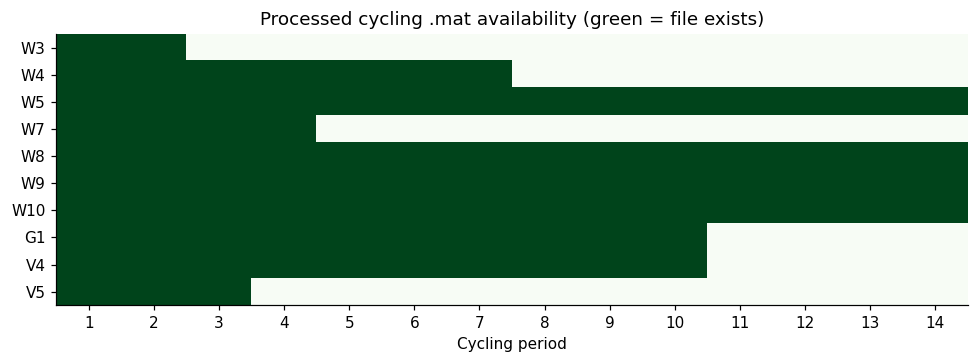

Cycling file size (MB): min 12 | median 104 | max 1408


In [ ]:
inv = inventory.copy()
inv["Top"] = inv.Path.str.extract(r"^/([^/]+)")[0]
inv["Ext"] = inv.Name.str.extract(r"(\.[A-Za-z0-9]+)$")[0].str.lower()
files_only = inv[inv.Type.eq("File")]

print("Total entries:", len(inv), "| folders:", int(inv.Type.eq("Folder").sum()), "| files:", len(files_only))
display(files_only.groupby(["Top", "Ext"]).agg(Files=("Name", "count"),
        Size_GB=("Size_MB", lambda s: round(s.sum() / 1e3, 2))).reset_index())

# processed MAT files = the ones used here
mat_all = files_only[files_only.Ext.eq(".mat")].copy()
cycling_index = mat_all[mat_all.Path.str.contains(r"(?i)/cycling_tests/cycling_\d+/_processed_mat/", na=False)].copy()
cycling_index["Cycling"] = cycling_index.Path.str.extract(r"(?i)/Cycling_(\d+)/")[0].astype(int)
cycling_index["Cell"] = cycling_index.Name.str.replace(r"(?i)\.mat$", "", regex=True)
cycling_index = cycling_index.drop_duplicates(["Cell", "Cycling"]).sort_values(["Cycling", "Cell"]).reset_index(drop=True)
assert not cycling_index.duplicated(["Cell", "Cycling"]).any()

print(f"\nProcessed cycling files: {len(cycling_index)} | periods: {cycling_index.Cycling.nunique()} | "
      f"cells: {cycling_index.Cell.nunique()} | total size: {cycling_index.Size_MB.sum()/1e3:.1f} GB")
unexpected = sorted(set(cycling_index.Cell) - set(CELLS_EXPECTED))
print("Cells not in expected list:", unexpected if unexpected else "none")

cov = pd.crosstab(cycling_index.Cell, cycling_index.Cycling).reindex(index=CELLS_EXPECTED, columns=range(1, N_CYCLING + 1), fill_value=0)
display(cov)
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(cov.to_numpy() > 0, aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set_yticks(range(len(cov))); ax.set_yticklabels(cov.index)
ax.set_xticks(range(N_CYCLING)); ax.set_xticklabels(range(1, N_CYCLING + 1))
ax.set_xlabel("Cycling period"); ax.set_title("Processed cycling .mat availability (green = file exists)")
ax.grid(False); fig.tight_layout(); savefig(fig, "01_cycling_file_coverage.png"); plt.show()

sz = cycling_index.Size_MB
print(f"Cycling file size (MB): min {sz.min():.0f} | median {sz.median():.0f} | max {sz.max():.0f}")

### README.xlsx — read every sheet (protocol, temperature, cell info, chronology)

The README is used to understand signal names and diagnostic chronology.

In [ ]:
def remote_bytes(path):
    # Read one selected file, without storing it on Drive.
    _, response = dbx.sharing_get_shared_link_file(
        url=DATASET_URL, path=path)
    return response.content

def remote_mat(path, tries=3):
    # Read one .mat file at a time; retry transient Dropbox errors.
    last = None
    for k in range(tries):
        try:
            raw = remote_bytes(path)
            data = loadmat(io.BytesIO(raw), simplify_cells=True)
            del raw
            return {k2: v for k2, v in data.items() if not k2.startswith("__")}
        except Exception as exc:
            last = exc
            time.sleep(3 * (k + 1))
    raise last

README = {}
try:
    xl = pd.ExcelFile(io.BytesIO(remote_bytes("/README.xlsx")))
    for sh in xl.sheet_names:
        df = pd.read_excel(xl, sheet_name=sh, header=None).dropna(how="all").dropna(axis=1, how="all")
        README[sh] = df
        print(f"\n===== SHEET: {sh}  {df.shape} =====")
        display(df.head(40))
except Exception as exc:
    print("README unavailable:", type(exc).__name__, str(exc)[:150])


===== SHEET: INFO  (2, 2) =====


,0,1
0,Last modified,2023-07-31
61,"In case of trouble downloading data from OSF,...",NaT



===== SHEET: Dataset_structure  (0, 0) =====


""



===== SHEET: Signals_description  (28, 2) =====


...

,0,1,2,3,4,5,6,7,8,9,10
0,NaN,W3,W4,W5,W7,W8,W9,W10,G1,V4,V5
1,Cycling_1,25,25,25,25,25,25,25,25,20,12
2,Cycling_2,50,50,50,50,50,50,50,5,25,6
3,Cycling_3,NaN,48,50,50,50,47,47,7,25,11
4,Cycling_4,NaN,9,34,16,23,22,24,25,25,-
5,Cycling_5,NaN,27,8,NaN,2,1,2,25,25,-
6,Cycling_6,NaN,17,20,NaN,1,1,3,25,25,-
7,Cycling_7,NaN,3,7,NaN,6,4,8,25,25,-
8,Cycling_8,NaN,-,25,NaN,28,29,29,25,24,-
9,Cycling_9,NaN,-,25,NaN,37,37,37,25,25,NaN



===== SHEET: Cycling_protocol  (9, 4) =====


,0,1,2,3
0,1) Aging cycling protocol (Table 2 of the paper),NaN,NaN,NaN
2,NaN,STEP,ACTION,EXIT CONDITION
3,NaN,1,CC charge at C-rate specified in the second co...,4V is reached
4,NaN,2,CV charge,Current below 50mA
5,NaN,3,CC charge at C/4,4.2V is reached
6,NaN,4,CV charge followed by 30min rest,Current below 50mA
7,NaN,5,CC discharge at C/4,20% discharged capacity (80% SOC)
8,NaN,6,UDDS discharge,60% discharged capacity (20% SOC)
27,2) Highlights on steps 5 and 6,NaN,NaN,NaN



===== SHEET: Temperature  (0, 0) =====


""


## 3 — Diagnostic capacity tests → SOH targets
All 15 checkpoints × 10 cells sit in one file. A record is valid only if time, current, voltage and capacity are aligned, finite, with strictly increasing time and a plausible final capacity. Missing records stay missing (never zero).

#### Build SOH ground truth

Reads capacity tests, validates individual traces, and computes SOH relative to the nominal **4.85 Ah** capacity. Output: the diagnostic-target table.

In [ ]:
CAP_PATH = "/diagnostic_tests/_processed_mat/capacity_test.mat"
capacity = remote_mat(CAP_PATH)
print({k: np.shape(v) for k, v in capacity.items()})

cells = [str(v).strip() for v in np.ravel(capacity["col_cell_label"])]
diags = [int(v) for v in np.ravel(capacity["row_diag_number"])]
print("Cells:", cells)
print("Diagnostics:", diags)
assert set(cells) == set(CELLS_EXPECTED), "Cell labels differ from the expected list"

def trace(d, key, i, j):
    # Some entries are scalar NaN instead of a time-series record.
    try:
        return np.asarray(d[key][i, j], dtype=float).ravel()
    except (TypeError, ValueError, KeyError, IndexError):
        return np.array([], dtype=float)

def capacity_record(i, j):
    t, cur, volt, q = (trace(capacity, k, i, j) for k in ["time", "curr", "vcell", "cap"])
    arrays = [t, cur, volt, q]
    if min(map(len, arrays)) < 2:
        return t, cur, volt, q, False, "Missing or short trace"
    if len(set(map(len, arrays))) != 1:
        return t, cur, volt, q, False, "Different signal lengths"
    if not all(np.isfinite(x).all() for x in arrays):
        return t, cur, volt, q, False, "Nonfinite values"
    if not np.all(np.diff(t) > 0):
        return t, cur, volt, q, False, "Invalid timestamps"
    if not (0 < q[-1] < 1.5 * NOMINAL_AH):
        return t, cur, volt, q, False, "Capacity outside checked range"
    return t, cur, volt, q, True, ""

rows = []
for i, d in enumerate(diags):
    for j, c in enumerate(cells):
        t, cur, volt, q, ok, why = capacity_record(i, j)
        rows.append(dict(Cell=c, Diagnostic=d, Valid=ok, Reason=why, Samples=len(t),
                         Capacity_Ah=float(q[-1]) if ok else np.nan))
capacity_df = pd.DataFrame(rows)
init = capacity_df[capacity_df.Diagnostic.eq(1)][["Cell", "Capacity_Ah"]].rename(columns={"Capacity_Ah": "Initial_capacity_Ah"})
capacity_df = capacity_df.merge(init, on="Cell", how="left", validate="many_to_one")
capacity_df["SOH_nominal_pct"] = 100 * capacity_df.Capacity_Ah / NOMINAL_AH
capacity_df["SOH_first_pct"] = 100 * capacity_df.Capacity_Ah / capacity_df.Initial_capacity_Ah

print(f"\nValid capacity records: {int(capacity_df.Valid.sum())} / {len(capacity_df)}")
display(capacity_df[~capacity_df.Valid].Reason.value_counts().to_frame("Rejected records"))
capacity_df.to_csv(OUT / "soh_targets.csv", index=False)
capacity_df[~capacity_df.Valid][["Cell", "Diagnostic", "Reason"]].to_csv(OUT / "capacity_quality_issues.csv", index=False)
display(capacity_df.head(8))

{'cap': (15, 10), 'col_cell_label': (10,), 'curr': (15, 10), 'row_diag_number': (15,), 'time': (15, 10), 'vcell': (15, 10)}
Cells: ['W3', 'W4', 'W5', 'W7', 'W8', 'W9', 'W10', 'G1', 'V4', 'V5']
Diagnostics: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

Valid capacity records: 101 / 150


,Rejected records
Reason,
Missing or short trace,49


,Cell,Diagnostic,Valid,Reason,Samples,Capacity_Ah,Initial_capacity_Ah,SOH_nominal_pct,SOH_first_pct
0,W3,1,True,,71560,4.820759,4.820759,99.397084,100.0
1,W4,1,True,,71587,4.822445,4.822445,99.431854,100.0
2,W5,1,True,,72092,4.856557,4.856557,100.135196,100.0
3,W7,1,True,,72475,4.882553,4.882553,100.671197,100.0
4,W8,1,True,,72392,4.876859,4.876859,100.553791,100.0
5,W9,1,True,,72353,4.874304,4.874304,100.501116,100.0
6,W10,1,True,,72227,4.865884,4.865884,100.327513,100.0
7,G1,1,True,,72781,4.903072,4.903072,101.094274,100.0


#### Visualize battery capacity fade

Plots diagnostic capacity and SOH by battery to inspect degradation and measurement variability.

,Group,Valid_diagnostics,Last_valid_diag,Initial_Ah,SOH_first,SOH_last,Total_fade_pp,Fade_pp_per_diag
Cell,,,,,,,,
W3,W,3,3,4.821,99.397,97.566,1.832,0.916
W4,W,8,8,4.822,99.432,93.498,5.933,0.895
W5,W,15,15,4.857,100.135,91.764,8.371,0.576
W7,W,4,4,4.883,100.671,97.340,3.332,1.139
W8,W,15,15,4.877,100.554,91.894,8.660,0.586
W9,W,15,15,4.874,100.501,92.034,8.467,0.571
W10,W,15,15,4.866,100.328,91.940,8.387,0.564
G1,G,11,11,4.903,101.094,94.841,6.253,0.546
V4,V,11,11,4.869,100.386,94.895,5.491,0.547



Capacity increases > 0.3 pp between consecutive checkpoints (measurement noise / recovery):


,Cell,Diagnostic,Rise_pp
0,W4,6,0.455


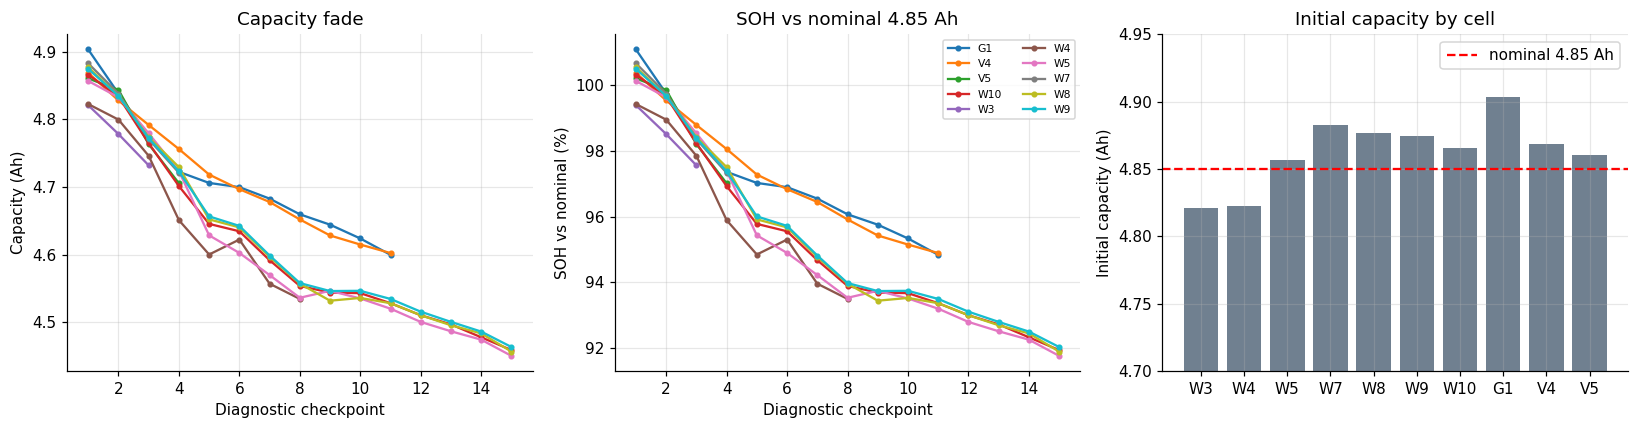

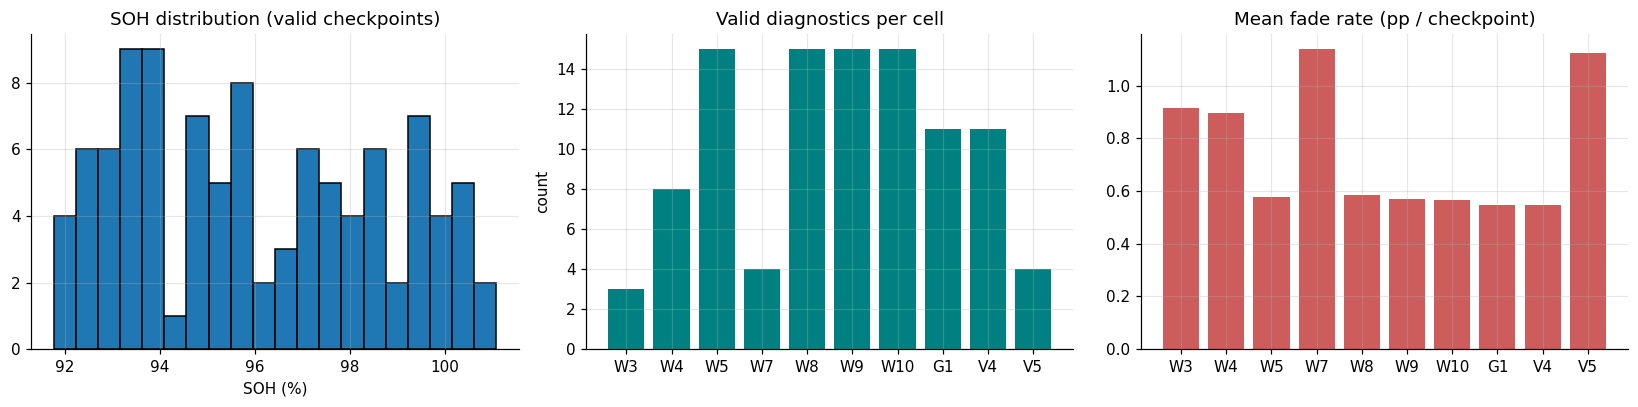

In [ ]:
# --- per-cell summary: how far each cell was aged, fade rate, initial capacity ---
v = capacity_df[capacity_df.Valid]
summ = []
for c, g in v.groupby("Cell"):
    slope, icpt = np.polyfit(g.Diagnostic, g.SOH_nominal_pct, 1) if len(g) >= 3 else (np.nan, np.nan)
    summ.append(dict(Cell=c, Group=c[0], Valid_diagnostics=len(g), Last_valid_diag=int(g.Diagnostic.max()),
                     Initial_Ah=g.Initial_capacity_Ah.iloc[0], SOH_first=g.SOH_nominal_pct.iloc[0],
                     SOH_last=g.SOH_nominal_pct.iloc[-1], Total_fade_pp=g.SOH_nominal_pct.iloc[0] - g.SOH_nominal_pct.iloc[-1],
                     Fade_pp_per_diag=-slope))
cell_summary = pd.DataFrame(summ).set_index("Cell").reindex(CELLS_EXPECTED)
display(cell_summary.round(3))
cell_summary.to_csv(OUT / "cell_summary.csv")

# monotonicity check: capacity should not rise noticeably between consecutive valid checkpoints
bad = []
for c, g in v.sort_values("Diagnostic").groupby("Cell"):
    d = g.SOH_nominal_pct.diff()
    for idx in d[d > 0.3].index:
        bad.append(dict(Cell=c, Diagnostic=int(g.loc[idx, "Diagnostic"]), Rise_pp=round(d[idx], 3)))
print("\nCapacity increases > 0.3 pp between consecutive checkpoints (measurement noise / recovery):")
display(pd.DataFrame(bad) if bad else "none")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for c, g in v.groupby("Cell"):
    axs[0].plot(g.Diagnostic, g.Capacity_Ah, marker=".", label=c)
    axs[1].plot(g.Diagnostic, g.SOH_nominal_pct, marker=".", label=c)
axs[0].set(xlabel="Diagnostic checkpoint", ylabel="Capacity (Ah)", title="Capacity fade")
axs[1].set(xlabel="Diagnostic checkpoint", ylabel="SOH vs nominal (%)", title="SOH vs nominal 4.85 Ah")
axs[1].legend(ncol=2, fontsize=7)
axs[2].bar(cell_summary.index, cell_summary.Initial_Ah, color="slategray")
axs[2].axhline(NOMINAL_AH, color="r", ls="--", label="nominal 4.85 Ah")
axs[2].set(ylim=(4.7, 4.95), ylabel="Initial capacity (Ah)", title="Initial capacity by cell"); axs[2].legend()
fig.tight_layout(); savefig(fig, "02_capacity_soh_trends.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].hist(v.SOH_nominal_pct, bins=20, edgecolor="k"); axs[0].set(title="SOH distribution (valid checkpoints)", xlabel="SOH (%)")
axs[1].bar(cell_summary.index, cell_summary.Valid_diagnostics, color="teal"); axs[1].set(title="Valid diagnostics per cell", ylabel="count")
axs[2].bar(cell_summary.index, cell_summary.Fade_pp_per_diag, color="indianred"); axs[2].set(title="Mean fade rate (pp / checkpoint)")
fig.tight_layout(); savefig(fig, "03_soh_distribution_and_cell_summary.png"); plt.show()

## 4 — HPPC and EIS availability (and a prior-checkpoint impedance feature)
HPPC pulse resistance is **not** derived here (pulse timing must be verified first). EIS high-frequency resistance R0 is extracted defensively, since the array layout is inspected at run time.


Identifies which diagnostic tests have usable signals. Availability does not imply every derived resistance metric is reliable.

HPPC keys: {'cap': (15, 10), 'col_cell_label': (10,), 'curr': (15, 10), 'row_diag_number': (15,), 'time': (15, 10), 'vcell': (15, 10)}
EIS keys : {'col_cell_label': (10,), 'freq': (15, 10), 'im_z': (15, 10), 're_z': (15, 10), 'row_diag_number': (15,), 'soc_level': (3,)}
EIS soc_level: [20 50 80]


Diagnostic,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
Capacity_valid,10,10,10,9,7,7,7,7,6,6,6,4,4,4,4
HPPC_valid,9,10,10,9,7,7,7,7,6,6,6,4,4,4,4
EIS_valid,4,6,6,5,4,4,4,4,4,4,4,3,3,3,3


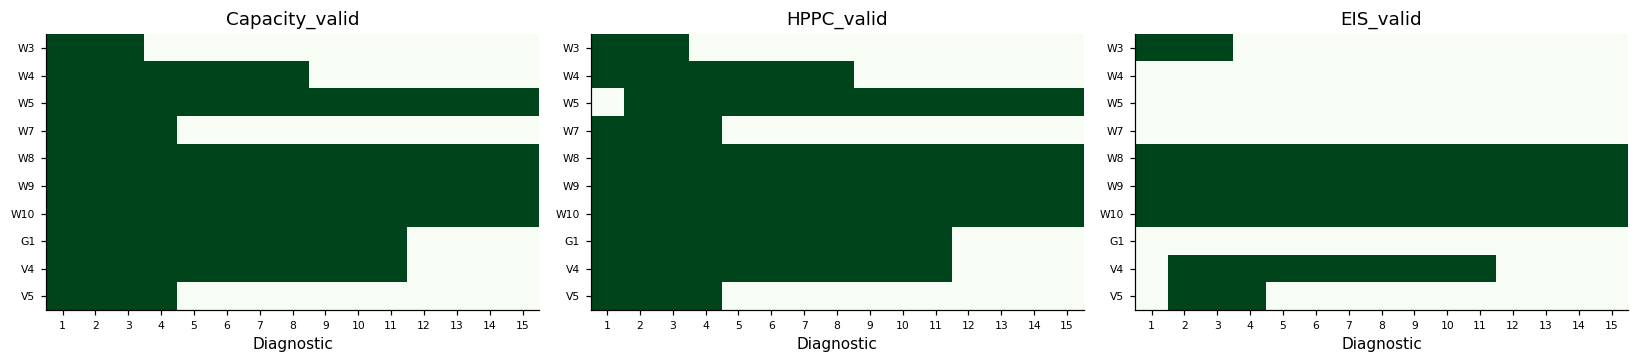

In [ ]:
def diag_valid(d, keys, i, j):
    arrs = [trace(d, k, i, j) for k in keys]
    if min(map(len, arrs)) < 2 or len(set(map(len, arrs))) != 1: return False
    if not all(np.isfinite(a).all() for a in arrs): return False
    return True

hppc = remote_mat("/diagnostic_tests/_processed_mat/HPPC_test.mat")
eis  = remote_mat("/diagnostic_tests/_processed_mat/EIS_test.mat")
print("HPPC keys:", {k: np.shape(v) for k, v in hppc.items()})
print("EIS keys :", {k: np.shape(v) for k, v in eis.items()})
print("EIS soc_level:", np.ravel(eis["soc_level"]))

avail = []
for i, d in enumerate(diags):
    for j, c in enumerate(cells):
        h_ok = diag_valid(hppc, ["time", "curr", "vcell"], i, j)
        e_ok = diag_valid(eis, ["freq", "re_z", "im_z"], i, j)
        avail.append(dict(Cell=c, Diagnostic=d, HPPC_valid=h_ok, EIS_valid=e_ok))
avail = pd.DataFrame(avail).merge(capacity_df[["Cell", "Diagnostic", "Valid"]].rename(columns={"Valid": "Capacity_valid"}),
                                  on=["Cell", "Diagnostic"])
display(avail.groupby("Diagnostic")[["Capacity_valid", "HPPC_valid", "EIS_valid"]].sum().T)
avail.to_csv(OUT / "diagnostic_availability.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, col in zip(axs, ["Capacity_valid", "HPPC_valid", "EIS_valid"]):
    m = avail.pivot(index="Cell", columns="Diagnostic", values=col).reindex(CELLS_EXPECTED).astype(float)
    ax.imshow(m.to_numpy(), aspect="auto", cmap="Greens", vmin=0, vmax=1)
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=7)
    ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(m.columns, fontsize=7)
    ax.set_title(col); ax.set_xlabel("Diagnostic"); ax.grid(False)
fig.tight_layout(); savefig(fig, "04_diagnostic_availability.png"); plt.show()

#### Explore an EIS resistance indicator

Computes an exploratory impedance-based indicator at the specified SOC. Treat this as a diagnostic proxy, not as definitive internal resistance.

Using SOC level index 1 (value 50.0) as the ~50 % SOC spectrum
EIS R0 extracted for 61 spectra


,count,mean,std,min,25%,50%,75%,max
EIS_R0_Ohm,61.0,0.025019,0.003849,0.023347,0.02409,0.024526,0.024866,0.053964


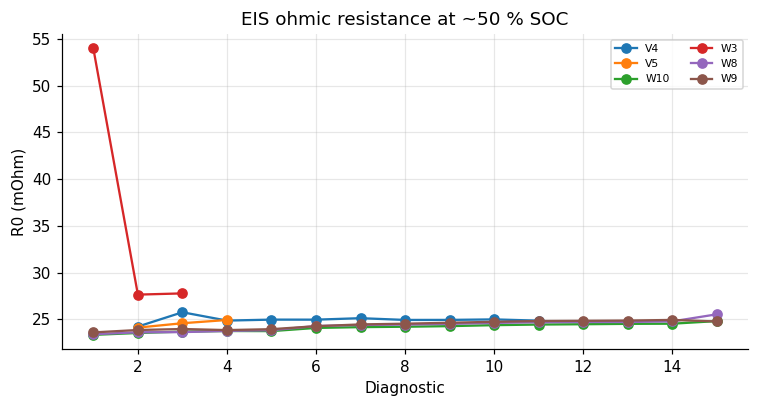

In [ ]:
# ---- EIS: ohmic resistance R0 at ~50 % SOC (zero crossing of Im Z; fallback = Re Z at highest frequency) ----
soc_levels = np.ravel(eis["soc_level"]).astype(float)
soc_target = 50.0 if soc_levels.max() > 1.5 else 0.5
soc_idx = int(np.argmin(np.abs(soc_levels - soc_target)))
print(f"Using SOC level index {soc_idx} (value {soc_levels[soc_idx]}) as the ~50 % SOC spectrum")

def as_soc_rows(a, n_soc):
    a = np.asarray(a, dtype=float)
    if a.ndim == 1: return a[None, :]
    if a.shape[0] == n_soc: return a
    if a.shape[-1] == n_soc: return a.T
    return a

def eis_r0(i, j):
    try:
        f = as_soc_rows(eis["freq"][i, j], len(soc_levels))
        re_ = as_soc_rows(eis["re_z"][i, j], len(soc_levels))
        im_ = as_soc_rows(eis["im_z"][i, j], len(soc_levels))
        k = min(soc_idx, re_.shape[0] - 1)
        f = f[min(k, f.shape[0] - 1)]; re_ = re_[k]; im_ = im_[k]
        ok = np.isfinite(f) & np.isfinite(re_) & np.isfinite(im_)
        f, re_, im_ = f[ok], re_[ok], im_[ok]
        if len(f) < 5: return np.nan
        o = np.argsort(-f); re_, im_ = re_[o], im_[o]          # high -> low frequency
        s = np.sign(im_)
        cross = np.flatnonzero(s[:-1] * s[1:] < 0)
        if len(cross):
            a = cross[0]; w = im_[a] / (im_[a] - im_[a + 1])
            return float(re_[a] + w * (re_[a + 1] - re_[a]))
        return float(re_[0])
    except Exception:
        return np.nan

eis_rows = [dict(Cell=c, Diagnostic=d, EIS_R0_Ohm=eis_r0(i, j))
            for i, d in enumerate(diags) for j, c in enumerate(cells)
            if avail[(avail.Cell == c) & (avail.Diagnostic == d)].EIS_valid.iloc[0]]
eis_r0_df = pd.DataFrame(eis_rows, columns=["Cell", "Diagnostic", "EIS_R0_Ohm"])
print("EIS R0 extracted for", int(eis_r0_df.EIS_R0_Ohm.notna().sum()), "spectra")
if eis_r0_df.EIS_R0_Ohm.notna().any():
    display(eis_r0_df.EIS_R0_Ohm.describe().to_frame().T)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for c, g in eis_r0_df.dropna().groupby("Cell"):
        ax.plot(g.Diagnostic, g.EIS_R0_Ohm * 1e3, marker="o", label=c)
    ax.set(xlabel="Diagnostic", ylabel="R0 (mOhm)", title="EIS ohmic resistance at ~50 % SOC"); ax.legend(ncol=2, fontsize=7)
    fig.tight_layout(); savefig(fig, "05_eis_r0_trend.png"); plt.show()
else:
    print("EIS R0 could not be extracted; the optional prior-EIS feature will be skipped.")
eis_r0_df.to_csv(OUT / "eis_r0.csv", index=False)

## 5 — Cycling signals: optional raw inspection and 50% selected-folder extraction
Selected Cycling 1, 3, 5, 7, 9, 11, 14 (seven of fourteen folders); reuse previously saved v4 features. No new diagnostic data are needed for selection.



Defines a variable lookup helper while leaving the optional high-memory raw plot disabled.

In [ ]:
# Optional raw plot is disabled to avoid downloading another huge MAT file.
# The get_var() helper is still needed by extract_features().
def get_var(data, prefix):
    matches = [v for k, v in data.items() if k.startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(f"Expected one variable starting {prefix}: got {len(matches)}")
    return np.asarray(matches[0], dtype=float).ravel()

SHOW_RAW_SAMPLE = False
print("Raw MAT preview skipped to protect Colab RAM")

Raw MAT preview skipped to protect Colab RAM


#### Define the cycling feature extractor

**Long but self-contained function definition.** Reads signal arrays supplied to it, calculates current/voltage statistics, charge/discharge throughput, quality indicators, and step summaries. This cell only **defines** functions; it does not process all MATLAB files.

In [ ]:
def _med(x, min_n=5):
    x = np.asarray(x, dtype=float)
    return float(np.median(x)) if x.size >= min_n else np.nan

def _q(x, p, min_n=5):
    x = np.asarray(x, dtype=float)
    return float(np.percentile(x, p)) if x.size >= min_n else np.nan

CHUNK = 3_000_000   # samples per chunk: bounds temporary memory regardless of file length

def extract_features(data, chunk=None):
    """Memory-bounded version: same features/definitions as before, pairwise work done in chunks."""
    CH = chunk or CHUNK
    t = get_var(data, "t_full_vec"); I = get_var(data, "I_full_vec"); V = get_var(data, "V_full_vec")
    st = get_var(data, "Step_Index_full_vec"); qd = get_var(data, "dis_cap_full_vec"); qc = get_var(data, "ch_cap_full_vec")
    n0 = len(t)
    if n0 < 100 or not all(len(x) == n0 for x in (I, V, st, qd, qc)):
        raise ValueError("Unaligned or too-short signals")
    fin = np.isfinite(t) & np.isfinite(I) & np.isfinite(V) & np.isfinite(st) & np.isfinite(qd) & np.isfinite(qc)
    if fin.sum() < 100:
        raise ValueError("Fewer than 100 finite samples")
    valid_fraction = float(fin.mean())
    if not fin.all():
        t, I, V, st, qd, qc = (x[fin] for x in (t, I, V, st, qd, qc))
    del fin
    n = len(t)

    # ---- timing QC (one temporary array, freed immediately) ----
    dt_all = np.diff(t)
    time_resets = int((dt_all < 0).sum()); gap_count = int((dt_all > MAX_DT_S).sum())
    pos_dt = dt_all[dt_all > 0]
    median_dt = float(np.median(pos_dt)) if pos_dt.size else np.nan
    del dt_all, pos_dt

    # ---- pass 1: current sign from the discharge / charge counters ----
    s_dis = s_ch = 0.0; n_dis = n_ch = 0
    for a in range(0, n - 1, CH):
        b = min(a + CH, n - 1); sl = slice(a, b + 1)
        Im = 0.5 * (I[sl][:-1] + I[sl][1:])
        md = np.diff(qd[sl]) > 1e-9; mc = np.diff(qc[sl]) > 1e-9
        s_dis += float(Im[md].sum()); n_dis += int(md.sum()); s_ch += float(Im[mc].sum()); n_ch += int(mc.sum())
    if n_dis < 10 or n_ch < 10:
        raise ValueError("Capacity counters never increase; cannot infer current sign")
    mean_I_when_dis = s_dis / n_dis; mean_I_when_ch = s_ch / n_ch
    s = 1.0 if mean_I_when_dis > 0 else -1.0
    sign_ok = (mean_I_when_dis * mean_I_when_ch) < 0
    Idp = I * s; del I                      # discharge-positive current

    vm = (V > V_LO) & (V < V_HI)

    # ---- pass 2: pairwise quantities, chunked ----
    T = w_dis = w_ch = 0.0
    dis_cnt = ch_cnt = dis_int = ch_int = 0.0
    sV = {"dis": [0.0, 0], "ch": [0.0, 0], "rest": [0.0, 0]}; sI = {"dis": [0.0, 0], "ch": [0.0, 0]}
    Rl, Rvl, Rdl = [], [], []
    for a in range(0, n - 1, CH):
        b = min(a + CH, n - 1); sl = slice(a, b + 1)
        tc, Ic, Vc, qdc, qcc, vmc = t[sl], Idp[sl], V[sl], qd[sl], qc[sl], vm[sl]
        dt = np.diff(tc); w = np.where((dt > 0) & (dt <= MAX_DT_S), dt, 0.0)
        Im = 0.5 * (Ic[:-1] + Ic[1:]); Vmid = 0.5 * (Vc[:-1] + Vc[1:]); vok = vmc[:-1] & vmc[1:]
        dqd = np.diff(qdc); dqc = np.diff(qcc)
        T += float(w.sum()); w_dis += float(w[Im > REST_A].sum()); w_ch += float(w[Im < -REST_A].sum())
        dis_cnt += float(dqd[dqd > 1e-9].sum()); ch_cnt += float(dqc[dqc > 1e-9].sum())
        pos, neg = np.maximum(Ic, 0.0), np.maximum(-Ic, 0.0)
        dis_int += float(np.sum(0.5 * (pos[:-1] + pos[1:]) * w) / 3600); ch_int += float(np.sum(0.5 * (neg[:-1] + neg[1:]) * w) / 3600)
        for key, msk in (("dis", (Im > REST_A) & vok), ("ch", (Im < -REST_A) & vok), ("rest", (np.abs(Im) <= REST_A) & vok)):
            sV[key][0] += float(Vmid[msk].sum()); sV[key][1] += int(msk.sum())
            if key in sI: sI[key][0] += float(Im[msk].sum()); sI[key][1] += int(msk.sum())
        dI, dV = np.diff(Ic), np.diff(Vc)
        sel = vok & (dt > 0) & (dt <= 0.5) & (np.abs(dI) >= R_DI_MIN)
        Rl.append(-dV[sel] / dI[sel]); Rvl.append(Vmid[sel]); Rdl.append(dI[sel])
        del tc, Ic, Vc, qdc, qcc, vmc, dt, w, Im, Vmid, vok, dqd, dqc, pos, neg, dI, dV, sel
    if T <= 0:
        raise ValueError("No valid time intervals")
    f_dis = w_dis / T; f_ch = w_ch / T
    R = np.concatenate(Rl); Rv = np.concatenate(Rvl); Rdi = np.concatenate(Rdl)
    keep = (R > 0) & (R < R_MAX_OHM); R, Rv, Rdi = R[keep], Rv[keep], Rdi[keep]

    # ---- step runs (global reduceat on the base arrays) ----
    chg = np.flatnonzero(np.diff(st) != 0) + 1
    starts = np.r_[0, chg]; ends = np.r_[chg, n] - 1
    cnt = (ends - starts + 1).astype(float)
    run_dis = np.maximum.reduceat(qd, starts) - np.minimum.reduceat(qd, starts)
    run_ch = np.maximum.reduceat(qc, starts) - np.minimum.reduceat(qc, starts)
    vsum = np.add.reduceat(np.where(vm, V, 0.0), starts); vn = np.add.reduceat(vm.astype(float), starts)
    runs = pd.DataFrame({"Step": st[starts].astype(int), "Dur_s": t[ends] - t[starts], "N": cnt,
                         "I_sum": np.add.reduceat(Idp, starts), "V_sum": vsum, "V_n": vn,
                         "Dis_Ah": run_dis, "Ch_Ah": run_ch})
    step_df = runs.groupby("Step").agg(N_runs=("N", "size"), Time_s=("Dur_s", "sum"), Samples=("N", "sum"),
                                        I_sum=("I_sum", "sum"), V_sum=("V_sum", "sum"), V_n=("V_n", "sum"),
                                        Dis_Ah=("Dis_Ah", "sum"), Ch_Ah=("Ch_Ah", "sum")).reset_index()
    step_df["Time_frac"] = step_df.Time_s / step_df.Time_s.sum()
    step_df["Mean_I"] = step_df.I_sum / step_df.Samples
    step_df["Mean_V"] = np.where(step_df.V_n > 0, step_df.V_sum / step_df.V_n.where(step_df.V_n > 0), np.nan)
    step_df = step_df.drop(columns=["I_sum", "V_sum", "V_n"])
    max_dis, max_ch, n_runs = float(run_dis.max()), float(run_ch.max()), int(len(starts))
    del runs, vsum, vn, run_dis, run_ch, chg, starts, ends, cnt

    # ---- whole-array statistics (sequential, one temporary at a time) ----
    pI = np.percentile(Idp, [1, 5, 95, 99])
    Vv = V[vm]
    pV = np.percentile(Vv, [1, 5, 50, 95]) if Vv.size else [np.nan] * 4
    feat = {
        "Samples": n0, "Valid_fraction": valid_fraction, "Median_dt_s": median_dt,
        "Time_resets": time_resets, "Gap_count": gap_count,
        "V_artifact_frac": float(1 - vm.mean()), "Current_sign_discharge": int(s), "Sign_consistent": bool(sign_ok),
        "Dis_counter_vs_integral": dis_cnt / dis_int if dis_int > 0 else np.nan,
        "Ch_counter_vs_integral": ch_cnt / ch_int if ch_int > 0 else np.nan,
        "Dis_Ah_integral": dis_int, "Ch_Ah_integral": ch_int,
        "Duration_h": float(T / 3600), "Dis_Ah_counter": dis_cnt, "Ch_Ah_counter": ch_cnt,
        "Coulombic_eff": ch_cnt / dis_cnt if dis_cnt > 0 else np.nan,
        "Frac_time_dis": float(f_dis), "Frac_time_ch": float(f_ch), "Frac_time_rest": float(1 - f_dis - f_ch),
        "N_runs": n_runs, "N_steps": int(len(step_df)),
        "Mean_I": float(Idp.mean()), "Std_I": float(Idp.std()), "RMS_I": float(np.sqrt(np.mean(Idp ** 2))),
        "Mean_abs_I": float(np.abs(Idp).mean()), "I_p01": float(pI[0]), "I_p05": float(pI[1]), "I_p95": float(pI[2]), "I_p99": float(pI[3]),
        "Mean_I_dis": sI["dis"][0] / sI["dis"][1] if sI["dis"][1] else np.nan,
        "Mean_I_ch": sI["ch"][0] / sI["ch"][1] if sI["ch"][1] else np.nan,
        "Mean_V": float(Vv.mean()), "Std_V": float(Vv.std()), "V_p01": float(pV[0]), "V_p05": float(pV[1]),
        "V_p50": float(pV[2]), "V_p95": float(pV[3]),
        "Mean_V_dis": sV["dis"][0] / sV["dis"][1] if sV["dis"][1] else np.nan,
        "Mean_V_ch": sV["ch"][0] / sV["ch"][1] if sV["ch"][1] else np.nan,
        "Mean_V_rest": sV["rest"][0] / sV["rest"][1] if sV["rest"][1] else np.nan,
        "R_inst_median": _med(R), "R_inst_p25": _q(R, 25), "R_inst_p75": _q(R, 75), "R_inst_n": int(R.size),
        "R_up_median": _med(R[Rdi > 0]), "R_down_median": _med(R[Rdi < 0]),
        "R_midV_median": _med(R[(Rv >= 3.6) & (Rv <= 3.9)]),
        "Max_step_dis_Ah": max_dis, "Max_step_ch_Ah": max_ch,
    }
    return feat, step_df

print("extract_features (lean, chunked) defined.")

extract_features (lean, chunked) defined.


#### Extract selected cycling files with checkpoints

**Main time-consuming step.** Filters the selected folders, reuses cached records, processes each remaining MATLAB file with the notebook’s memory-isolation logic, logs failures, and saves features/step summaries. Review final coverage rather than assuming every selected file succeeded.

In [ ]:
# 50% SAMPLING: 7 of 14 cycling folders. Each file runs in its OWN child process:
# if a huge file runs out of memory only the child dies, the file is logged as skipped, and the loop continues.
import os, gc, time, ctypes, psutil, pickle, tempfile, resource
import multiprocessing as mp
from pathlib import Path
from scipy.io import whosmat

SELECTED_CYCLING = [1, 3, 5, 7, 9, 11, 14]
FEATURE_FILE = OUT / "cycling_features_v4.csv"
STEP_FILE = OUT / "cycling_step_summary_v4.csv"
ISSUE_FILE = OUT / "cycling_processing_issues_v4.csv"
RETRY_CRASHED = False            # True = try again the files that crashed before
NEEDED = ("t_full_vec", "I_full_vec", "V_full_vec", "Step_Index_full_vec", "dis_cap_full_vec", "ch_cap_full_vec")

cache = pd.read_csv(FEATURE_FILE) if FEATURE_FILE.exists() else pd.DataFrame()
if cache.empty:
    cache = pd.DataFrame(columns=["Cell", "Cycling", "Extractor_version"])
if not cache.empty and not cache.Extractor_version.eq(EXTRACTOR_VERSION).all():
    raise ValueError("Existing cache uses a different extractor version. Do not mix versions.")
assert "inventory" in globals(), "Run the dataset-inventory cells first."
inv_files = inventory[inventory.Type.eq("File")].copy()
inv_files["Cycling"] = pd.to_numeric(inv_files.Path.str.extract(r"(?i)/cycling_tests/cycling_(\d+)/_processed_mat/")[0], errors="coerce")
all_cycling = inv_files.loc[inv_files.Cycling.notna() & inv_files.Path.str.lower().str.endswith(".mat")].copy()
all_cycling["Cycling"] = all_cycling.Cycling.astype(int)
all_cycling["Cell"] = all_cycling.Name.str.extract(r"(?i)(W10|W[345789]|G1|V[45])", expand=False).str.upper()
assert not all_cycling.Cell.isna().any(), "Cell name extraction needs checking"
cycling_index = all_cycling.loc[all_cycling.Cycling.isin(SELECTED_CYCLING)].copy()
assert not cycling_index.duplicated(["Cell", "Cycling"]).any()
print("Total Cycling MAT files:", len(all_cycling), "| selected:", len(cycling_index), "in folders", SELECTED_CYCLING)

def clean_memory():
    gc.collect()
    try: ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception: pass

def remote_mat_lean(path, tries=3):
    # stream the download to local disk (not RAM) and load ONLY the six needed signals
    last = None
    for k in range(tries):
        tmp = os.path.join(tempfile.gettempdir(), f"_tmp_cycling_{os.getpid()}.mat")
        try:
            dbx.sharing_get_shared_link_file_to_file(tmp, url=DATASET_URL, path=path)
            want = [n for n, _, _ in whosmat(tmp) if n.startswith(NEEDED)]
            data = loadmat(tmp, variable_names=want, simplify_cells=True)
            return {k2: v for k2, v in data.items() if not k2.startswith("__")}
        except Exception as exc:
            last = exc; time.sleep(3 * (k + 1))
        finally:
            if os.path.exists(tmp): os.remove(tmp)
    raise last

def _worker(path, out_file):
    try:
        obj = remote_mat_lean(path)
        feat, sdf = extract_features(obj)
        res = ("ok", feat, sdf)
    except MemoryError:
        res = ("memory", "MemoryError", None)
    except Exception as exc:
        res = ("error", repr(exc)[:250], None)
    with open(out_file, "wb") as fh: pickle.dump(res, fh)

def process_one(path):
    out_file = os.path.join(tempfile.gettempdir(), "_feat_result.pkl")
    if os.path.exists(out_file): os.remove(out_file)
    p = mp.get_context("fork").Process(target=_worker, args=(path, out_file))
    p.start(); p.join()
    if os.path.exists(out_file):
        with open(out_file, "rb") as fh: status, a, b = pickle.load(fh)
        os.remove(out_file); return status, a, b
    return "crashed", f"child killed (exit code {p.exitcode}) - out of memory", None

cache_keys = set(zip(cache.Cell.astype(str), cache.Cycling.astype(int))) if len(cache) else set()
selected_keys = set(zip(cycling_index.Cell, cycling_index.Cycling.astype(int)))
crashed_before = set()
if ISSUE_FILE.exists() and not RETRY_CRASHED:
    _iss = pd.read_csv(ISSUE_FILE)
    crashed_before = {(str(r.Cell), int(r.Cycling)) for r in _iss.itertuples()
                      if any(w in str(r.Issue).lower() for w in ("crashed", "memory", "killed"))}
    if crashed_before: print("Skipping files that crashed earlier (set RETRY_CRASHED=True to retry):", sorted(crashed_before))
print("Already cached in the selected subset:", len(cache_keys & selected_keys))

remaining = cycling_index.loc[[((str(r.Cell), int(r.Cycling)) not in cache_keys) and ((str(r.Cell), int(r.Cycling)) not in crashed_before)
                               for r in cycling_index.itertuples()]].sort_values(["Cycling", "Cell"])
print("To process now:", len(remaining))

t0 = time.time()
for k, r in enumerate(remaining.itertuples(), 1):
    print(f"[{k}/{len(remaining)}] {r.Cell} C{r.Cycling} ({r.Size_MB:.0f} MB) ...", end=" ", flush=True)
    status, feat, sdf = process_one(r.Path)
    if status == "ok":
        sdf.insert(0, "Cycling", int(r.Cycling)); sdf.insert(0, "Cell", str(r.Cell))
        if STEP_FILE.exists():
            es = pd.read_csv(STEP_FILE)
            es = es.loc[~(es.Cell.eq(str(r.Cell)) & es.Cycling.eq(int(r.Cycling)))]
            es.to_csv(STEP_FILE, index=False); del es
        sdf.to_csv(STEP_FILE, mode="a", header=not STEP_FILE.exists() or STEP_FILE.stat().st_size == 0, index=False)
        cache = pd.concat([cache, pd.DataFrame([{"Cell": str(r.Cell), "Cycling": int(r.Cycling), "Extractor_version": EXTRACTOR_VERSION, **feat}])], ignore_index=True)
        cache.to_csv(FEATURE_FILE, index=False); cache_keys.add((str(r.Cell), int(r.Cycling)))
        print(f"ok | {(time.time()-t0)/60:.1f} min | child peak so far {resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss/1e6:.1f} GB", flush=True)
    else:
        pd.DataFrame([{"Cell": str(r.Cell), "Cycling": int(r.Cycling), "Issue": f"{status}: {feat}"}]).to_csv(
            ISSUE_FILE, mode="a", index=False, header=not ISSUE_FILE.exists())
        print(f"SKIPPED ({status}: {str(feat)[:70]})", flush=True)
    feat = sdf = None; clean_memory()

cache["Cycling"] = cache["Cycling"].astype(int); cache["Cell"] = cache["Cell"].astype(str)   # keep proper dtypes even if the cache started empty
cycling_features = cache.loc[cache.Cycling.isin(SELECTED_CYCLING)].copy().drop_duplicates(["Cell", "Cycling"], keep="last").reset_index(drop=True)
step_summary = pd.read_csv(STEP_FILE) if STEP_FILE.exists() else pd.DataFrame()
if len(step_summary): step_summary = step_summary.loc[step_summary.Cycling.isin(SELECTED_CYCLING)].copy()
print("\nSelected features available:", len(cycling_features), "/", len(selected_keys))
print("Missing selected pairs:", sorted(selected_keys - set(zip(cycling_features.Cell, cycling_features.Cycling))) or "none - extraction complete")

Total Cycling MAT files: 92 | selected: 47 in folders [1, 3, 5, 7, 9, 11, 14]
Already cached in the selected subset: 26
To process now: 21
[1/21] G1 C5 (94 MB) ... ok | 0.1 min | child peak so far 1.2 GB
[2/21] V4 C5 (107 MB) ... ok | 0.4 min | child peak so far 1.2 GB
[3/21] W10 C5 (184 MB) ... ok | 0.6 min | child peak so far 1.7 GB
[4/21] W5 C5 (301 MB) ... ok | 0.9 min | child peak so far 2.2 GB
[5/21] W8 C5 (291 MB) ... ok | 1.2 min | child peak so far 2.2 GB
[6/21] G1 C7 (93 MB) ... ok | 1.4 min | child peak so far 2.2 GB
[7/21] V4 C7 (106 MB) ... ok | 1.5 min | child peak so far 2.2 GB
[8/21] W10 C7 (1018 MB) ... ok | 2.5 min | child peak so far 5.7 GB
[9/21] W5 C7 (304 MB) ... ok | 2.9 min | child peak so far 5.7 GB
[10/21] W8 C7 (990 MB) ... ok | 3.9 min | child peak so far 5.7 GB
[11/21] W9 C7 (978 MB) ... ok | 4.8 min | child peak so far 5.7 GB
[12/21] G1 C9 (93 MB) ... ok | 5.0 min | child peak so far 5.7 GB
[13/21] V4 C9 (103 MB) ... ok | 5.1 min | child peak so far 5.7 GB

### Extraction quality control

#### Audit the extracted measurements

Checks sampling, timing, current sign, voltage artifacts, and counter–integration agreement. Investigate flagged recordings; do not automatically discard every threshold failure.

,count,mean,std,min,25%,50%,75%,max
Samples,47.0,1.453520e+07,1.671072e+07,812948.0000,6.222934e+06,7.723332e+06,1.547642e+07,7.182849e+07
Valid_fraction,47.0,1.000000e+00,0.000000e+00,1.0000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
Median_dt_s,47.0,1.000000e-01,1.000000e-04,0.0996,1.000000e-01,1.000000e-01,1.000000e-01,1.002000e-01
Time_resets,47.0,6.596000e-01,2.229000e+00,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.300000e+01
Gap_count,47.0,1.064000e-01,3.117000e-01,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
V_artifact_frac,47.0,0.000000e+00,0.000000e+00,0.0000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
Current_sign_discharge,47.0,-1.000000e+00,0.000000e+00,-1.0000,-1.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000e+00
Dis_counter_vs_integral,47.0,1.002200e+00,4.600000e-03,1.0000,1.000400e+00,1.000400e+00,1.000500e+00,1.022000e+00
Ch_counter_vs_integral,47.0,1.002500e+00,4.700000e-03,1.0000,1.000700e+00,1.000800e+00,1.000900e+00,1.022400e+00
R_inst_n,47.0,2.127660e+01,1.328400e+01,1.0000,9.000000e+00,2.400000e+01,2.400000e+01,4.900000e+01


Current sign convention (+1: discharge is positive): {-1: 47}
Files with inconsistent sign inference: 0
Files with time resets: 9 | files with sampling gaps: 5
Counter / integral agreement (should be ~1):


,count,mean,std,min,25%,50%,75%,max
Dis_counter_vs_integral,47.0,1.0022,0.0046,1.0,1.0004,1.0004,1.0005,1.0220
Ch_counter_vs_integral,47.0,1.0025,0.0047,1.0,1.0007,1.0008,1.0009,1.0224


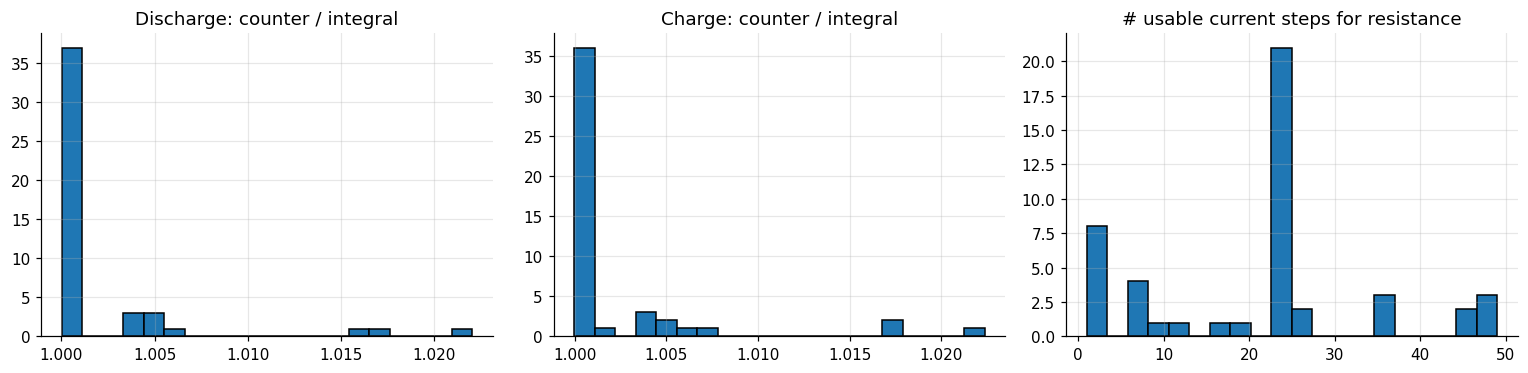

In [ ]:
qc_cols = ["Samples", "Valid_fraction", "Median_dt_s", "Time_resets", "Gap_count", "V_artifact_frac",
           "Current_sign_discharge", "Sign_consistent", "Dis_counter_vs_integral", "Ch_counter_vs_integral", "R_inst_n"]
display(cycling_features[qc_cols].describe().T.round(4))
print("Current sign convention (+1: discharge is positive):", cycling_features.Current_sign_discharge.value_counts().to_dict())
print("Files with inconsistent sign inference:", int((~cycling_features.Sign_consistent).sum()))
print("Files with time resets:", int((cycling_features.Time_resets > 0).sum()),
      "| files with sampling gaps:", int((cycling_features.Gap_count > 0).sum()))
r = cycling_features[["Dis_counter_vs_integral", "Ch_counter_vs_integral"]]
print("Counter / integral agreement (should be ~1):")
display(r.describe().T.round(4))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
axs[0].hist(r.Dis_counter_vs_integral.dropna(), bins=20, edgecolor="k"); axs[0].set(title="Discharge: counter / integral")
axs[1].hist(r.Ch_counter_vs_integral.dropna(), bins=20, edgecolor="k"); axs[1].set(title="Charge: counter / integral")
axs[2].hist(cycling_features.R_inst_n, bins=20, edgecolor="k"); axs[2].set(title="# usable current steps for resistance")
fig.tight_layout(); savefig(fig, "09_extraction_qc.png"); plt.show()
if (~cycling_features.Sign_consistent).any() or cycling_features.Current_sign_discharge.nunique() > 1:
    print("WARNING: current sign inference is not uniform across files - inspect before modelling.")

## 6 — Pair cycling features with SOH targets (chronology verified from data)
Each row is one **cell × cycling period k**. Inputs come from period *k*; the target is SOH measured at **Diagnostic k+1** (the checkpoint after that period). Cumulative-age features include period *k* and everything before it, and are only used when the history 1..k is complete.

#### Match predictors to measured SOH



In [ ]:
cf = cycling_features.sort_values(["Cell", "Cycling"]).reset_index(drop=True).copy()
cf["Cell_Group"] = cf.Cell.str[0]
g = cf.groupby("Cell")

# --- cumulative age features (valid only when EVERY earlier period is present) ---
cf["Cum_Discharge_Ah"]   = g.Dis_Ah_counter.cumsum()
cf["Cum_Charge_Ah"]      = g.Ch_Ah_counter.cumsum()
cf["Cum_Throughput_Ah"]  = cf.Cum_Discharge_Ah + cf.Cum_Charge_Ah
cf["Cum_EFC"]            = cf.Cum_Discharge_Ah / NOMINAL_AH
cf["Cum_Hours"]          = g.Duration_h.cumsum()
cf["EFC_period"]         = cf.Dis_Ah_counter / NOMINAL_AH
cf["History_complete"]   = cf.groupby("Cell").Cycling.transform(lambda s: s.eq(np.arange(1, len(s) + 1))).astype(bool)
for name in ["Cum_Discharge_Ah", "Cum_Charge_Ah", "Cum_Throughput_Ah", "Cum_EFC", "Cum_Hours"]:
    cf.loc[~cf.History_complete, name] = np.nan     # the 50 % subset has deliberate gaps

# --- features relative to the same cell's FIRST VALID period (usually period 1) ---
REL_BASE = ["R_inst_median", "R_midV_median", "Max_step_dis_Ah", "Mean_V_dis", "Mean_V", "Std_V"]
for c in REL_BASE:
    first = cf.dropna(subset=[c]).sort_values("Cycling").groupby("Cell")[c].first()
    cf[c + "_rel_c1"] = cf[c] / cf.Cell.map(first)

# --- targets: Diagnostic k+1 ; previous diagnostic kept only as optional autoregressive columns ---
cap = capacity_df[["Cell", "Diagnostic", "Valid", "Capacity_Ah", "SOH_nominal_pct", "SOH_first_pct"]]
cf["Diag_No"] = cf.Cycling + 1
pairs = cf.merge(cap.rename(columns={"Diagnostic": "Diag_No"}), on=["Cell", "Diag_No"], how="left", validate="one_to_one")
prev = cap.rename(columns={"Diagnostic": "Cycling", "Capacity_Ah": "Capacity_prev_Ah",
                           "SOH_nominal_pct": "SOH_prev_nominal_pct"})[["Cell", "Cycling", "Capacity_prev_Ah", "SOH_prev_nominal_pct"]]
pairs = pairs.merge(prev, on=["Cell", "Cycling"], how="left", validate="one_to_one")
if len(eis_r0_df):
    pairs = pairs.merge(eis_r0_df.rename(columns={"Diagnostic": "Cycling", "EIS_R0_Ohm": "Prev_EIS_R0_Ohm"}),
                        on=["Cell", "Cycling"], how="left", validate="one_to_one")
else:
    pairs["Prev_EIS_R0_Ohm"] = np.nan
pairs = pairs.rename(columns={"Cell": "Cell_ID", "Cycling": "Cycling_No", "Valid": "Target_valid"})
pairs["Target_valid"] = pairs.Target_valid.fillna(False).astype(bool) & pairs[TARGET].notna()
print("Candidate pairs:", len(pairs), "| with valid target:", int(pairs.Target_valid.sum()))

# ---------- chronology check for a SUBSET of periods ----------
# For each cell: the selected periods that should exist are those whose target diagnostic (k+1) was measured.
chk = []
for c in CELLS_EXPECTED:
    cyc = sorted(pairs[pairs.Cell_ID == c].Cycling_No)
    vd = sorted(capacity_df[(capacity_df.Cell == c) & capacity_df.Valid].Diagnostic)
    last_d = max(vd) if vd else 0
    expected_periods = [p for p in SELECTED_CYCLING if p <= last_d - 1]
    chk.append(dict(Cell=c, Found=cyc, Expected=expected_periods, As_expected=(cyc == expected_periods),
                    N_valid_diag=len(vd), Last_valid_diag=last_d))
chrono = pd.DataFrame(chk).set_index("Cell")
display(chrono)
CHRONOLOGY_CONSISTENT = bool(chrono.As_expected.all())
print("Selected periods match the measured diagnostics:", CHRONOLOGY_CONSISTENT)
if not CHRONOLOGY_CONSISTENT:
    print("A cell shows Found != Expected: a selected file is missing (skipped/crashed) - re-run the extraction cell.")

Candidate pairs: 47 | with valid target: 47


,Found,Expected,As_expected,N_valid_diag,Last_valid_diag
Cell,,,,,
W3,[1],[1],True,3,3
W4,"[1, 3, 5, 7]","[1, 3, 5, 7]",True,8,8
W5,"[1, 3, 5, 7, 9, 11, 14]","[1, 3, 5, 7, 9, 11, 14]",True,15,15
W7,"[1, 3]","[1, 3]",True,4,4
W8,"[1, 3, 5, 7, 9, 11, 14]","[1, 3, 5, 7, 9, 11, 14]",True,15,15
W9,"[1, 3, 5, 7, 9, 11, 14]","[1, 3, 5, 7, 9, 11, 14]",True,15,15
W10,"[1, 3, 5, 7, 9, 11, 14]","[1, 3, 5, 7, 9, 11, 14]",True,15,15
G1,"[1, 3, 5, 7, 9]","[1, 3, 5, 7, 9]",True,11,11
V4,"[1, 3, 5, 7, 9]","[1, 3, 5, 7, 9]",True,11,11


Selected periods match the measured diagnostics: True


### Feature catalogue


| Group | Meaning | Note |
|---|---|---|
| `age` | cycle number, cumulative Ah / hours | usually the strongest SOH predictor; decide if "age" is allowed in your problem statement |
| `usage` | what the cell did in this period (Ah, time mix, steps) | descriptive of protocol |
| `vi_stats` | current / voltage statistics | whole-period, protocol-sensitive |
| `resistance` | voltage drop per A at current steps | physical ageing indicator |
| `cap_proxy` | largest single-step charge/discharge Ah | capacity-like, measured in cycling not in the target diagnostic |
| `relative` | feature ÷ same cell's period-1 value | removes cell-to-cell offsets |
| `prior_diag` | previous diagnostic SOH / EIS | **autoregressive; excluded from the model CSV** |

#### Define candidate model features

Groups potential predictors, filters for valid targets, and handles incompleteness for EDA/export.

**Modeling caution:** any global imputation or target-informed feature choice must not be reused as an unbiased held-out validation procedure.

In [ ]:
FEATURE_GROUPS = {
    "age":        ["Cycling_No", "Cum_Discharge_Ah", "Cum_Throughput_Ah", "Cum_Hours"],
    "usage":      ["Duration_h", "Dis_Ah_counter", "Ch_Ah_counter", "Coulombic_eff", "Frac_time_dis", "Frac_time_ch",
                   "Frac_time_rest", "N_runs", "N_steps"],
    "vi_stats":   ["Mean_I", "Std_I", "RMS_I", "Mean_abs_I", "I_p01", "I_p05", "I_p95", "I_p99", "Mean_I_dis", "Mean_I_ch",
                   "Mean_V", "Std_V", "V_p01", "V_p05", "V_p50", "V_p95", "Mean_V_dis", "Mean_V_ch", "Mean_V_rest"],
    "resistance": ["R_inst_median", "R_inst_p25", "R_inst_p75", "R_up_median", "R_down_median", "R_midV_median"],
    "cap_proxy":  ["Max_step_dis_Ah", "Max_step_ch_Ah"],
    "relative":   [c + "_rel_c1" for c in REL_BASE],
}
PRIOR_DIAG = ["SOH_prev_nominal_pct", "Capacity_prev_Ah", "Prev_EIS_R0_Ohm"]
GROUP_OF = {f: gname for gname, fs in FEATURE_GROUPS.items() for f in fs}
TARGET_COLS = ["SOH_nominal_pct", "SOH_first_pct", "Capacity_Ah"]
ID_COLS = ["Cell_ID", "Cell_Group", "Diag_No"]          # Cycling_No is an age FEATURE, not an ID
candidate = [f for f in GROUP_OF if f in pairs.columns]

elig = pairs.Target_valid & pairs[TARGET].notna()
pairs["Candidate_eligible"] = elig

# Keep a feature if it is missing in at most MAX_MISSING_FRAC of the rows; fill its few gaps with the feature median.
# (Features that are mostly empty, e.g. cumulative Ah in the 50 % subset, are dropped.)
MAX_MISSING_FRAC = 0.25
block = pairs.loc[elig, candidate].replace([np.inf, -np.inf], np.nan)
miss = pd.DataFrame({"n_missing": block.isna().sum(), "missing_frac": block.isna().mean(),
                     "group": [GROUP_OF[f] for f in block.columns]})
print("Features with missing values (before handling):")
display(miss[miss.n_missing > 0].sort_values("missing_frac", ascending=False).round(3))

FEATURES = [f for f in candidate if miss.loc[f, "missing_frac"] <= MAX_MISSING_FRAC and block[f].nunique() > 1]
dropped = sorted(set(candidate) - set(FEATURES))
pairs["Any_feature_imputed"] = False
for f in FEATURES:
    col = pairs[f].replace([np.inf, -np.inf], np.nan)
    m = elig & col.isna()
    if m.any():
        pairs.loc[m, "Any_feature_imputed"] = True
        pairs.loc[elig, f] = col[elig].fillna(col[elig].median())
print(f"\nEligible rows: {int(elig.sum())} / {len(pairs)} | usable features: {len(FEATURES)} | rows with an imputed value: "
      f"{int(pairs.loc[elig, 'Any_feature_imputed'].sum())}")
print("Dropped (mostly empty or constant):", dropped)

data = pairs.loc[elig].sort_values(["Cell_ID", "Cycling_No"]).reset_index(drop=True)
y = data[TARGET]
assert data[FEATURES].notna().all().all(), "NaN left in model features"
assert not set(FEATURES) & set(TARGET_COLS + ID_COLS + PRIOR_DIAG), "Leakage guard failed"

Features with missing values (before handling):


,n_missing,missing_frac,group
R_up_median,47,1.000,resistance
R_midV_median,43,0.915,resistance
R_midV_median_rel_c1,43,0.915,relative
Cum_Hours,37,0.787,age
Cum_Throughput_Ah,37,0.787,age
Cum_Discharge_Ah,37,0.787,age
R_inst_median,8,0.170,resistance
R_inst_p75,8,0.170,resistance
R_inst_p25,8,0.170,resistance
R_down_median,8,0.170,resistance



Eligible rows: 47 / 47 | usable features: 40 | rows with an imputed value: 8
Dropped (mostly empty or constant): ['Cum_Discharge_Ah', 'Cum_Hours', 'Cum_Throughput_Ah', 'R_midV_median', 'R_midV_median_rel_c1', 'R_up_median']


## 7 — Regression EDA
All analysis below uses the eligible rows only. Same-cell rows are **not independent**, so every performance-type number is computed with leave-one-cell-out grouping.

#### Check observations and SOH coverage

Shows records per battery, coverage across selected periods, and SOH distribution. Remember that many rows come from the same physical cell.

Rows: 47 | cells: 10 | features: 40 | rows/feature: 1.2


,Rows,First_period,Last_period,SOH_min,SOH_max
Cell_ID,,,,,
W3,1,1,1,98.52,98.52
W4,4,1,7,93.50,98.96
W5,7,1,14,91.76,99.64
W7,2,1,3,97.34,99.75
W8,7,1,14,91.89,99.68
W9,7,1,14,92.03,99.68
W10,7,1,14,91.94,99.66
G1,5,1,9,95.34,99.75
V4,5,1,9,95.15,99.54


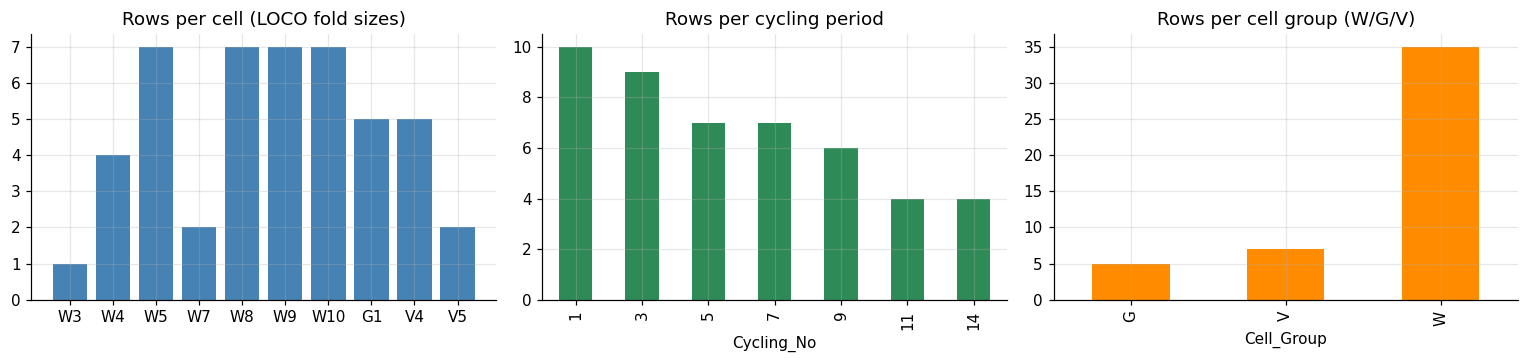

Missing values in eligible features: 0 | infinite: 0
NOTE: some cells contribute <3 rows; per-fold LOCO R2 is meaningless there - pool out-of-fold predictions for metrics.

Target SOH_nominal_pct: mean 95.88 | sd 2.54 | min 91.76 | max 99.87 | skew 0.11 | excess kurtosis -1.18 | Shapiro p=0.0132
A mean-only predictor has MAE ~ 2.15 pp and RMSE ~ 2.51 pp: models must beat this under LOCO.


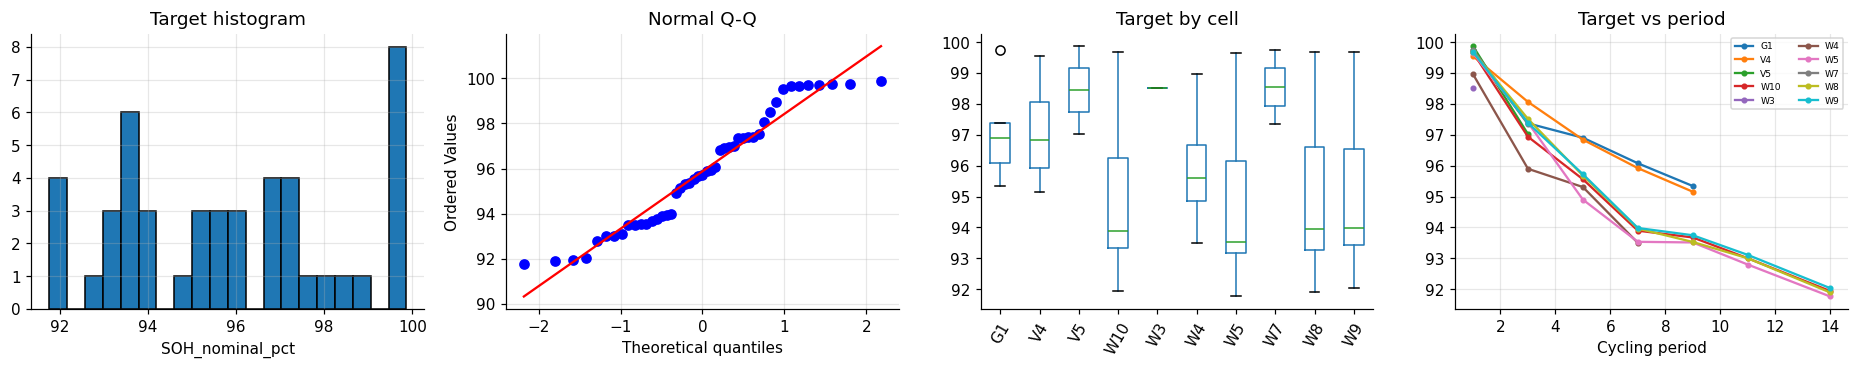

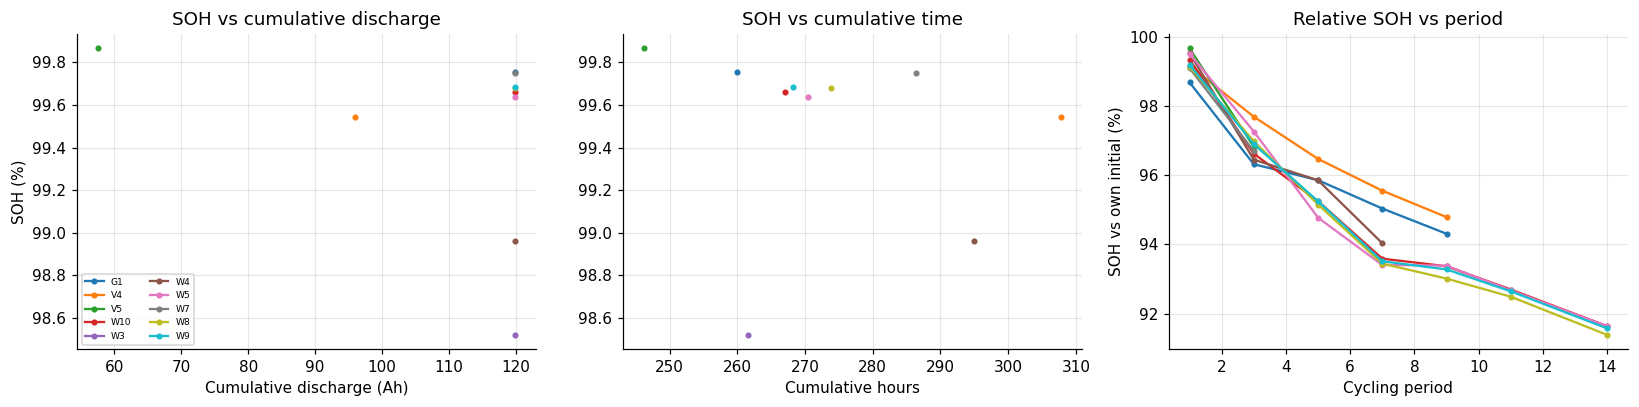

In [ ]:
# ---------- 7.1 sample size, balance, missingness ----------
print(f"Rows: {len(data)} | cells: {data.Cell_ID.nunique()} | features: {len(FEATURES)} | rows/feature: {len(data)/len(FEATURES):.1f}")
bal = data.groupby("Cell_ID").agg(Rows=("Cycling_No", "size"), First_period=("Cycling_No", "min"), Last_period=("Cycling_No", "max"),
                                   SOH_min=(TARGET, "min"), SOH_max=(TARGET, "max")).reindex(CELLS_EXPECTED)
display(bal.round(2))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
axs[0].bar(bal.index, bal.Rows, color="steelblue"); axs[0].set(title="Rows per cell (LOCO fold sizes)")
data.groupby("Cycling_No").size().plot.bar(ax=axs[1], color="seagreen"); axs[1].set(title="Rows per cycling period")
data.groupby("Cell_Group").size().plot.bar(ax=axs[2], color="darkorange"); axs[2].set(title="Rows per cell group (W/G/V)")
fig.tight_layout(); savefig(fig, "10_sample_balance.png"); plt.show()
print("Missing values in eligible features:", int(data[FEATURES].isna().sum().sum()),
      "| infinite:", int(np.isinf(data[FEATURES].to_numpy(float)).sum()))
if data.Cell_ID.value_counts().min() < 3:
    print("NOTE: some cells contribute <3 rows; per-fold LOCO R2 is meaningless there - pool out-of-fold predictions for metrics.")

# ---------- 7.2 target ----------
sk, ku = stats.skew(y), stats.kurtosis(y)
sh = stats.shapiro(y)
print(f"\nTarget {TARGET}: mean {y.mean():.2f} | sd {y.std():.2f} | min {y.min():.2f} | max {y.max():.2f} | skew {sk:.2f} | excess kurtosis {ku:.2f} | Shapiro p={sh.pvalue:.3g}")
print(f"A mean-only predictor has MAE ~ {np.mean(np.abs(y - y.mean())):.2f} pp and RMSE ~ {y.std(ddof=0):.2f} pp: models must beat this under LOCO.")
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
axs[0].hist(y, bins=20, edgecolor="k"); axs[0].set(title="Target histogram", xlabel=TARGET)
stats.probplot(y, dist="norm", plot=axs[1]); axs[1].set_title("Normal Q-Q")
data.boxplot(column=TARGET, by="Cell_ID", ax=axs[2], grid=False); axs[2].set(title="Target by cell", xlabel=""); plt.sca(axs[2]); plt.xticks(rotation=60)
for c, gg in data.groupby("Cell_ID"): axs[3].plot(gg.Cycling_No, gg[TARGET], marker=".", label=c)
axs[3].set(title="Target vs period", xlabel="Cycling period"); axs[3].legend(ncol=2, fontsize=6)
plt.suptitle(""); fig.tight_layout(); savefig(fig, "11_target_overview.png"); plt.show()

# SOH vs age
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for c, gg in data.groupby("Cell_ID"):
    axs[0].plot(gg.Cum_Discharge_Ah, gg[TARGET], marker=".", label=c)
    axs[1].plot(gg.Cum_Hours, gg[TARGET], marker=".")
    axs[2].plot(gg.Cycling_No, gg.SOH_first_pct, marker=".")
axs[0].set(xlabel="Cumulative discharge (Ah)", ylabel="SOH (%)", title="SOH vs cumulative discharge"); axs[0].legend(ncol=2, fontsize=6)
axs[1].set(xlabel="Cumulative hours", title="SOH vs cumulative time")
axs[2].set(xlabel="Cycling period", ylabel="SOH vs own initial (%)", title="Relative SOH vs period")
fig.tight_layout(); savefig(fig, "12_soh_vs_age.png"); plt.show()

#### Describe electrical features and usage patterns

Examines numerical distributions and trajectories. Differences in rest fraction or test duration may reflect recording conditions rather than battery health.

,group,mean,std,min,50%,max,skew,CV
Cycling_No,age,5.8511,4.0485,1.0000,5.0000,14.0000,0.5317,0.6919
Duration_h,usage,468.8554,452.4690,31.0284,273.8880,2005.1007,2.6549,0.9651
Dis_Ah_counter,usage,110.5943,63.1019,4.6631,115.1980,236.4384,0.2865,0.5706
Ch_Ah_counter,usage,113.0754,65.1567,8.1157,115.1306,246.9697,0.3899,0.5762
Coulombic_eff,usage,1.0459,0.1329,0.8459,1.0104,1.7404,3.8632,0.1270
Frac_time_dis,usage,0.2682,0.1356,0.0069,0.3361,0.3807,-1.1581,0.5056
Frac_time_ch,usage,0.3728,0.1899,0.0078,0.4508,0.5498,-1.1743,0.5093
Frac_time_rest,usage,0.3590,0.3214,0.1417,0.1738,0.9853,1.2558,0.8951
N_runs,usage,154.2553,98.7321,2.0000,175.0000,350.0000,0.1429,0.6401
N_steps,usage,11.2340,2.5127,2.0000,12.0000,12.0000,-3.3856,0.2237


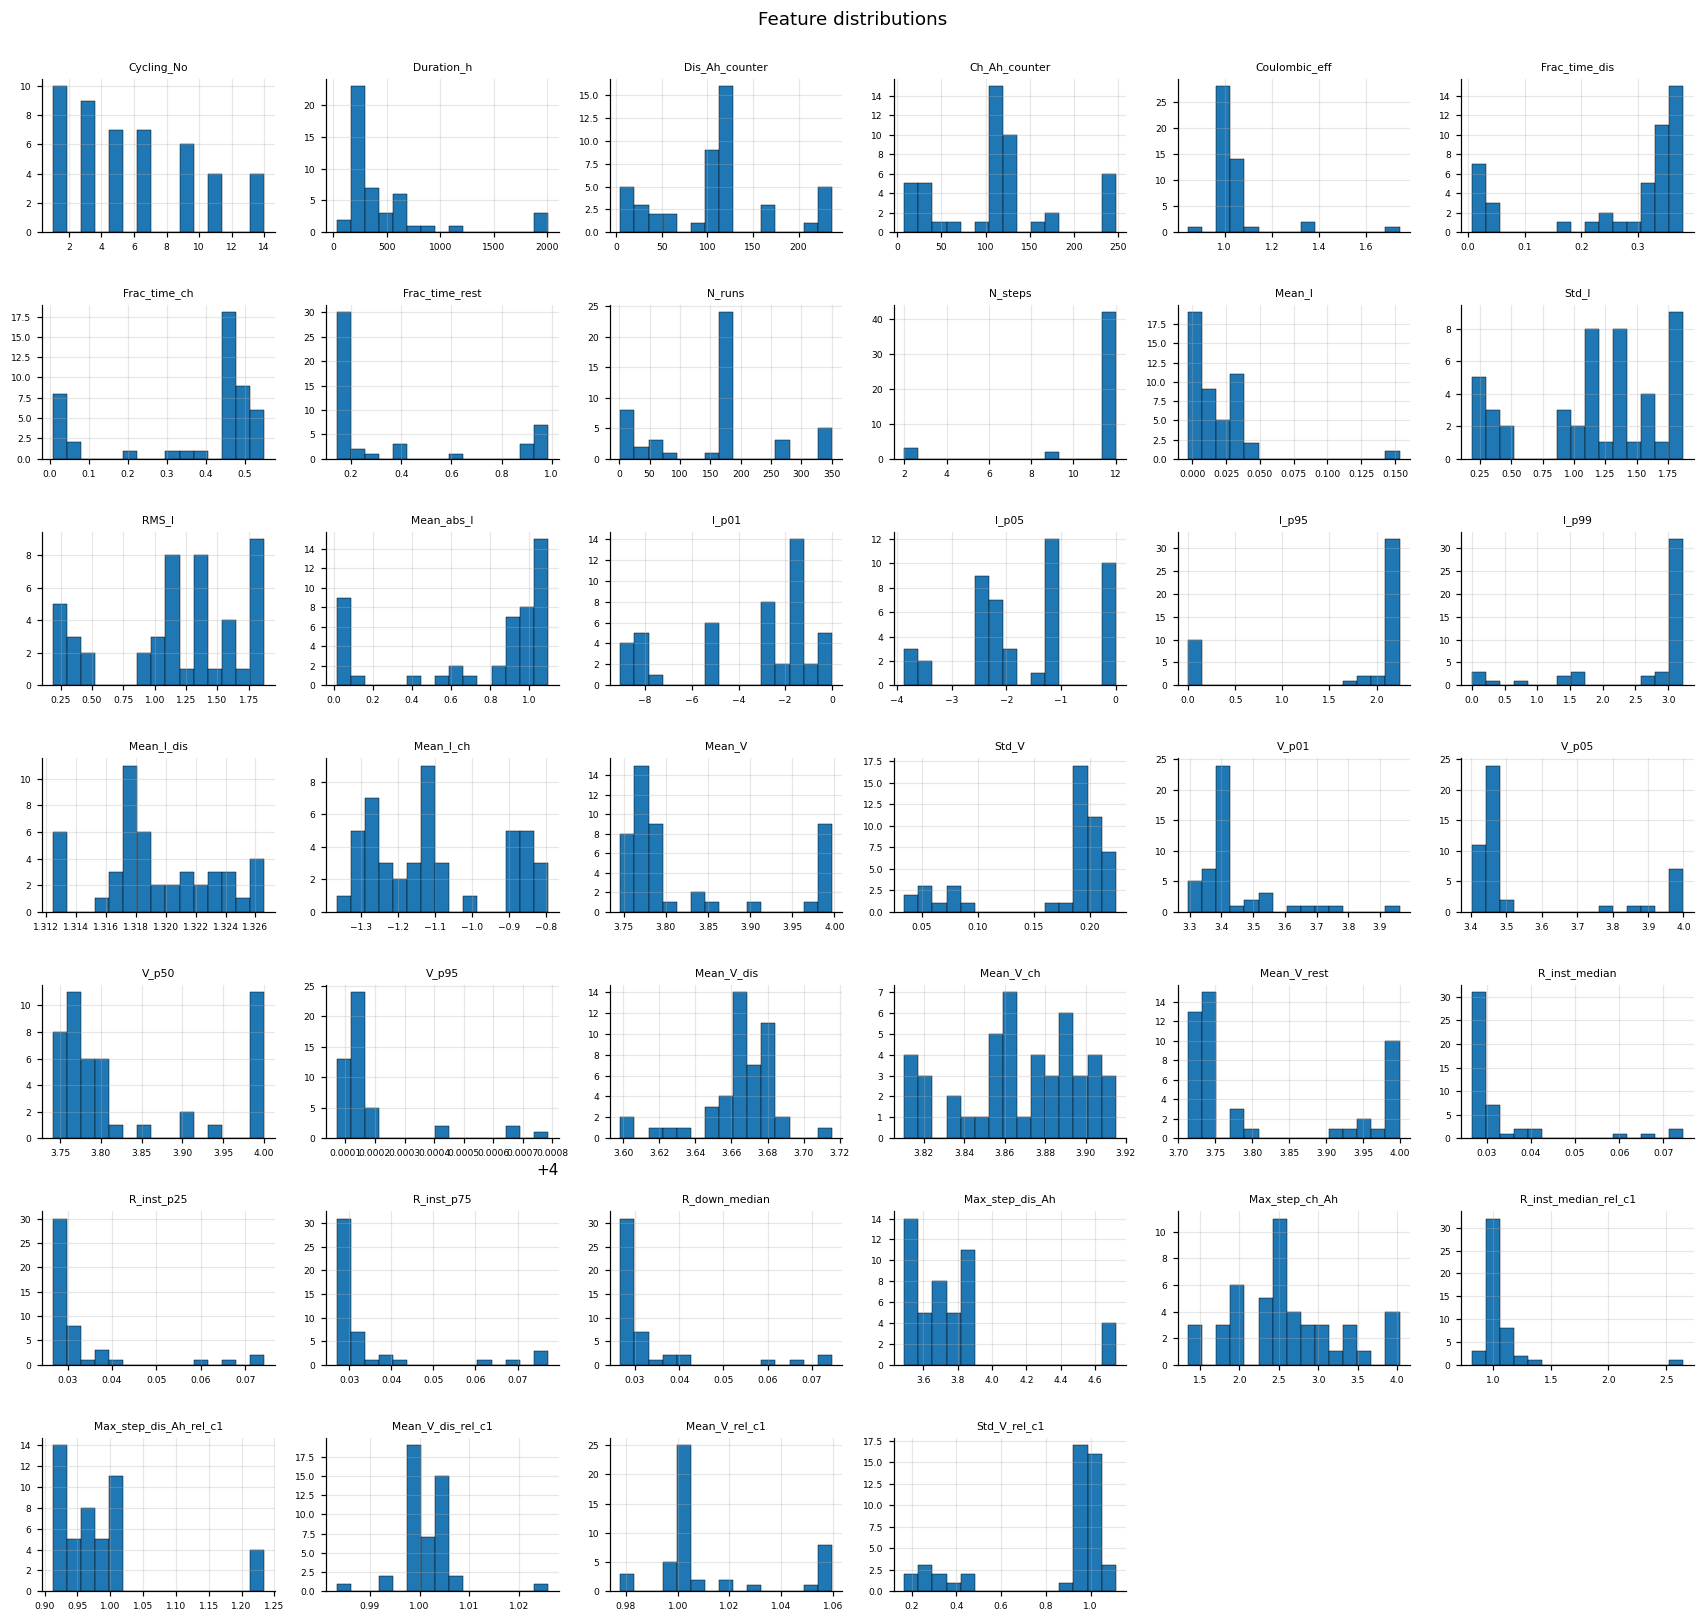

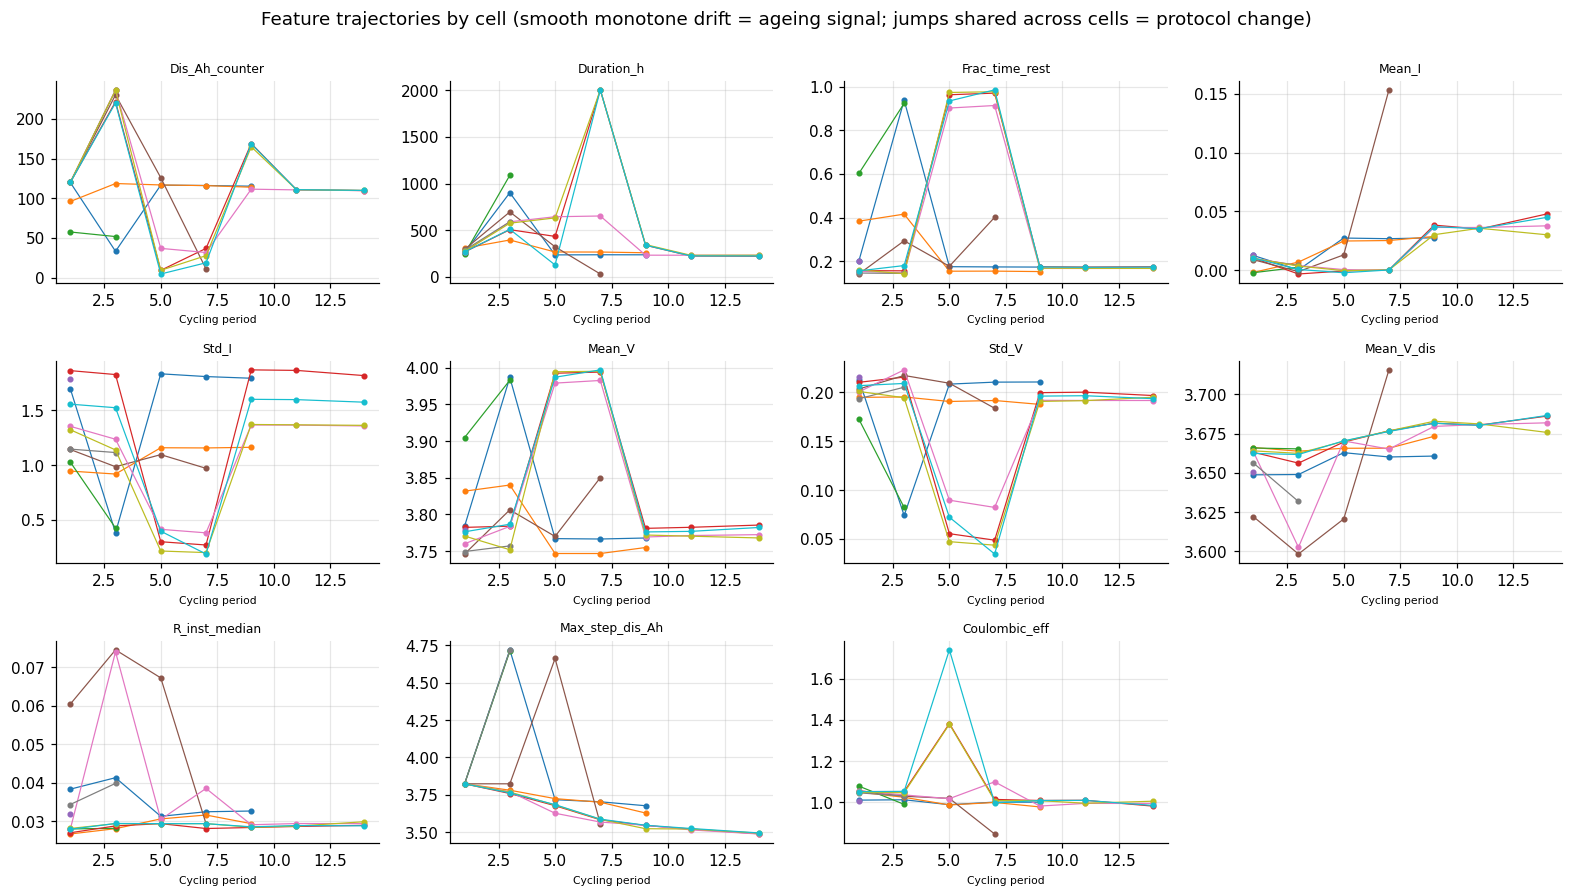

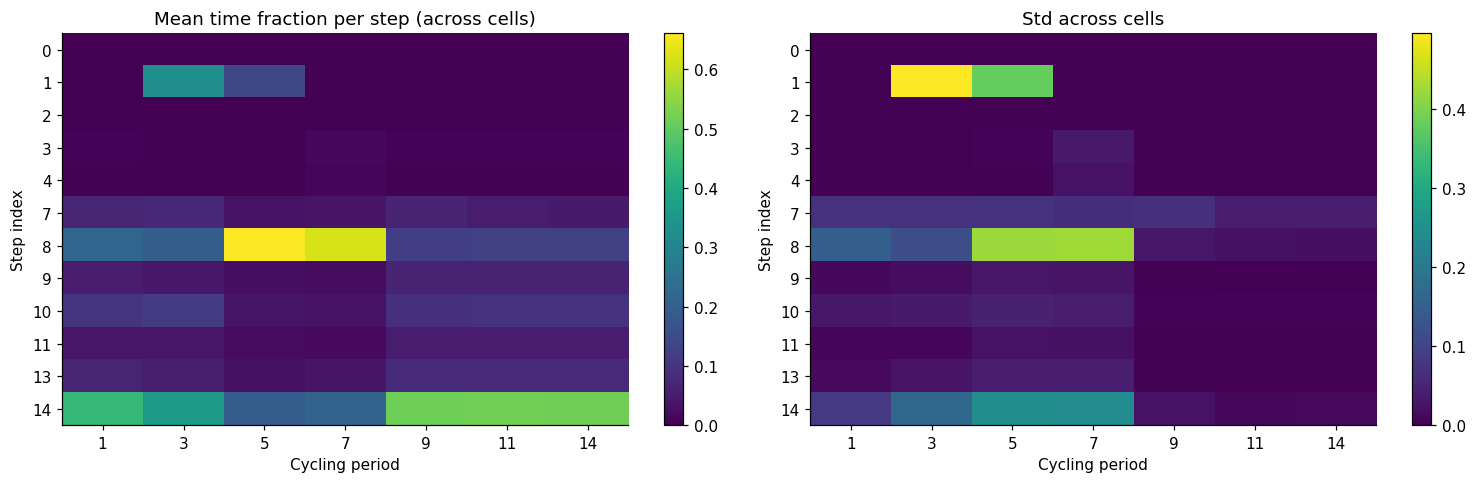

Step-time composition similarity to period 1 (1.0 = identical protocol mix):


,1,3,5,7,9,11,14
corr_with_period1,1.0,0.689,0.535,0.605,0.97,0.97,0.97


In [ ]:
# ---------- 7.3 feature overview, distributions ----------
desc = data[FEATURES].describe().T
desc["skew"] = data[FEATURES].skew(); desc["CV"] = desc["std"] / desc["mean"].abs().replace(0, np.nan)
desc["group"] = [GROUP_OF[f] for f in desc.index]
display(desc[["group", "mean", "std", "min", "50%", "max", "skew", "CV"]].round(4))

fig, axs = grid(len(FEATURES), ncols=6, w=2.6, h=2.1)
for ax, f in zip(axs, FEATURES):
    ax.hist(data[f], bins=15, edgecolor="k", linewidth=.3); ax.set_title(f, fontsize=7); ax.tick_params(labelsize=6)
fig.suptitle("Feature distributions", y=1.0); fig.tight_layout(); savefig(fig, "13_feature_distributions.png"); plt.show()

# ---------- 7.4 drift with age: trend (signal) vs jumps (protocol change) ----------
KEY = [f for f in ["Dis_Ah_counter", "Duration_h", "Frac_time_rest", "Mean_I", "Std_I", "Mean_V", "Std_V", "Mean_V_dis",
                   "R_inst_median", "R_midV_median", "Max_step_dis_Ah", "Coulombic_eff"] if f in FEATURES]
fig, axs = grid(len(KEY), ncols=4, w=3.6, h=2.7)
for ax, f in zip(axs, KEY):
    for c, gg in data.groupby("Cell_ID"): ax.plot(gg.Cycling_No, gg[f], marker=".", lw=.8)
    ax.set_title(f, fontsize=8); ax.set_xlabel("Cycling period", fontsize=7)
fig.suptitle("Feature trajectories by cell (smooth monotone drift = ageing signal; jumps shared across cells = protocol change)", y=1.0)
fig.tight_layout(); savefig(fig, "14_feature_trajectories.png"); plt.show()

# ---------- 7.5 protocol consistency across periods (step composition) ----------
sd = step_summary.merge(data[["Cell_ID", "Cycling_No"]].rename(columns={"Cell_ID": "Cell", "Cycling_No": "Cycling"}),
                        on=["Cell", "Cycling"])
if len(sd):
    pv = sd.pivot_table(index="Step", columns="Cycling", values="Time_frac", aggfunc="mean").fillna(0)
    sdv = sd.pivot_table(index="Step", columns="Cycling", values="Time_frac", aggfunc="std").fillna(0)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, m, ttl in zip(axs, [pv, sdv], ["Mean time fraction per step (across cells)", "Std across cells"]):
        im = ax.imshow(m.to_numpy(), aspect="auto", cmap="viridis"); ax.grid(False)
        ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index); ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(m.columns)
        ax.set_xlabel("Cycling period"); ax.set_ylabel("Step index"); ax.set_title(ttl); fig.colorbar(im, ax=ax)
    fig.tight_layout(); savefig(fig, "15_step_composition.png"); plt.show()
    # per-period profile similarity: correlation of each period's step-time vector with period 1
    base = pv.get(1)
    if base is not None:
        sim = pd.Series({k: np.corrcoef(base, pv[k])[0, 1] for k in pv.columns}, name="corr_with_period1")
        print("Step-time composition similarity to period 1 (1.0 = identical protocol mix):")
        display(sim.round(3).to_frame().T)
    step_summary.to_csv(OUT / "step_summary_all.csv", index=False)

#### Identify outliers and correlated variables

Flags unusual observations and investigates redundant features. Flags are prompts to inspect, not automatic deletion instructions.

Flagged observations: 292


,flags
Feature,
Dis_Ah_counter,21
Ch_Ah_counter,17
Frac_time_rest,15
Mean_V_rest,15
V_p01,15
Mean_V_rel_c1,15
Duration_h,12
V_p50,12
I_p95,12


Flags by period (clusters in one period => protocol change, not noise): {1: 20, 3: 98, 5: 82, 7: 86, 9: 6}


,Feature,Cell_ID,Cycling_No,Value,Robust_z,IQR_flag
255,R_inst_median_rel_c1,W5,3,2.650635,35.62,True
88,Frac_time_rest,W9,7,0.985286,27.99,True
86,Frac_time_rest,W8,7,0.976755,27.69,True
237,R_inst_p75,W7,3,0.077238,27.59,True
85,Frac_time_rest,W8,5,0.973406,27.58,True
80,Frac_time_rest,W10,7,0.970404,27.47,True
79,Frac_time_rest,W10,5,0.962899,27.22,True
112,I_p95,W10,5,0.000304,-26.99,True
116,I_p95,W8,5,0.000368,-26.99,True
119,I_p95,W9,7,0.000846,-26.98,True


,Spearman,Pearson,abs_spearman,group
Cycling_No,-0.956,-0.939,0.956,age
Max_step_dis_Ah_rel_c1,0.904,0.463,0.904,relative
Max_step_dis_Ah,0.888,0.463,0.888,cap_proxy
Mean_V_dis,-0.753,-0.509,0.753,vi_stats
Mean_V_dis_rel_c1,-0.752,-0.498,0.752,relative
Max_step_ch_Ah,0.677,0.616,0.677,cap_proxy
Std_V_rel_c1,0.590,0.232,0.590,relative
Coulombic_eff,0.557,0.122,0.557,usage
Mean_I,-0.543,-0.471,0.543,vi_stats
Mean_I_dis,-0.518,-0.509,0.518,vi_stats


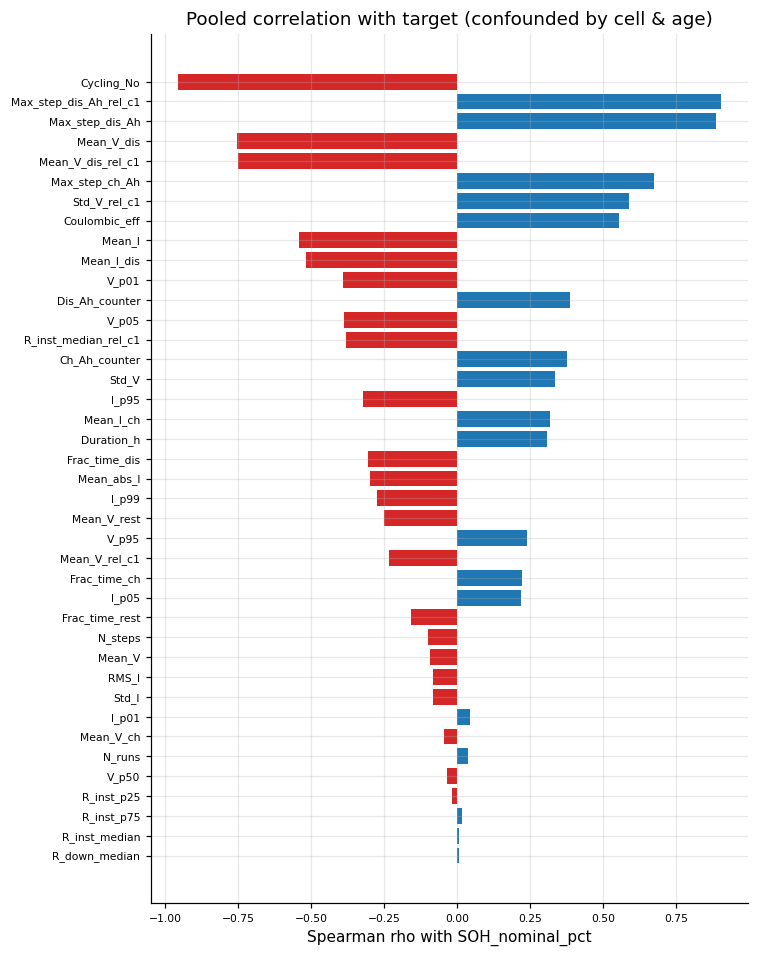

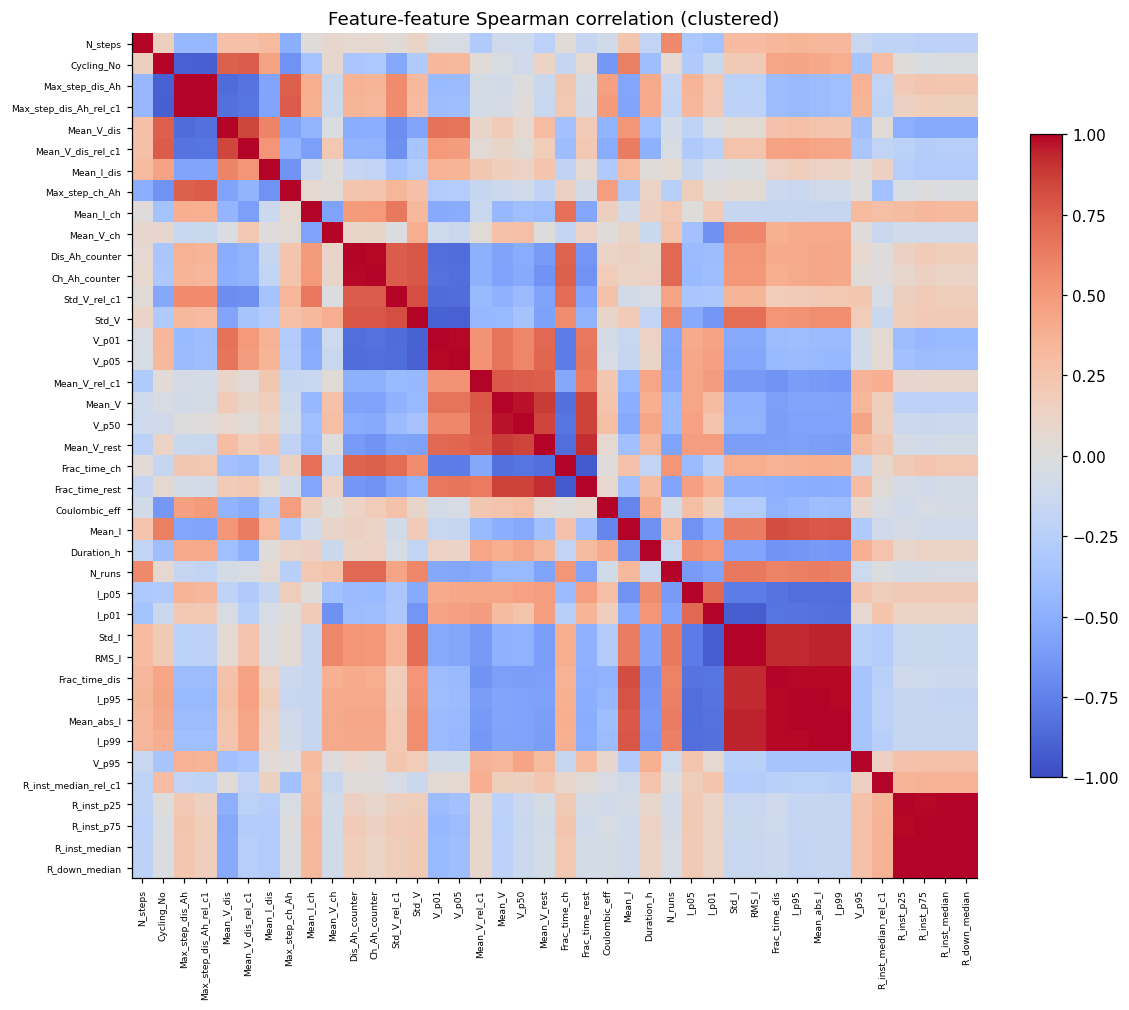

Feature pairs with |rho| > 0.95: 17


,A,B,rho
374,Std_I,RMS_I,1.000
727,R_inst_median,R_down_median,1.000
726,R_inst_median,R_inst_p75,0.998
744,R_inst_p75,R_down_median,0.998
432,Mean_abs_I,I_p99,0.995
736,R_inst_p25,R_down_median,0.995
725,R_inst_median,R_inst_p25,0.995
431,Mean_abs_I,I_p95,0.994
761,Max_step_dis_Ah,Max_step_dis_Ah_rel_c1,0.993
504,I_p95,I_p99,0.992


Variance inflation factors (>10 = strongly collinear):


,VIF
Max_step_dis_Ah,2.759807e+09
Max_step_dis_Ah_rel_c1,2.758381e+09
RMS_I,1.317816e+08
Std_I,1.295026e+08
R_inst_p25,1.373703e+05
Mean_V,1.239060e+05
Std_V,1.210003e+05
I_p95,8.103560e+04
Frac_time_dis,6.502710e+04
Mean_abs_I,4.985970e+04


In [ ]:
# ---------- 7.6 outliers (flag, never delete) ----------
def robust_z(x):
    med = np.median(x); mad = np.median(np.abs(x - med))
    return 0.6745 * (x - med) / mad if mad > 0 else np.zeros_like(x)

out_rows = []
for f in FEATURES + [TARGET]:
    z = robust_z(data[f].to_numpy(float))
    q1, q3 = data[f].quantile([.25, .75]); iqr = q3 - q1
    iqr_flag = (data[f] < q1 - 1.5 * iqr) | (data[f] > q3 + 1.5 * iqr)
    for i in np.flatnonzero((np.abs(z) > 3.5) | iqr_flag.to_numpy()):
        out_rows.append(dict(Feature=f, Cell_ID=data.Cell_ID[i], Cycling_No=data.Cycling_No[i], Value=data[f][i],
                             Robust_z=round(z[i], 2), IQR_flag=bool(iqr_flag[i])))
outliers = pd.DataFrame(out_rows, columns=["Feature", "Cell_ID", "Cycling_No", "Value", "Robust_z", "IQR_flag"])
outliers.to_csv(OUT / "eda_outlier_candidates.csv", index=False)
print("Flagged observations:", len(outliers))
display(outliers.groupby("Feature").size().sort_values(ascending=False).head(15).to_frame("flags"))
by_period = outliers.groupby("Cycling_No").size()
print("Flags by period (clusters in one period => protocol change, not noise):", by_period.to_dict())
display(outliers.reindex(outliers.Robust_z.abs().sort_values(ascending=False).index).head(15))

# ---------- 7.7 correlation with target, collinearity ----------
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
sp = data[FEATURES + [TARGET]].corr(method="spearman")
pe = data[FEATURES + [TARGET]].corr(method="pearson")
rank = pd.DataFrame({"Spearman": sp[TARGET].drop(TARGET), "Pearson": pe[TARGET].drop(TARGET)})
rank["abs_spearman"] = rank.Spearman.abs(); rank["group"] = [GROUP_OF[f] for f in rank.index]
rank = rank.sort_values("abs_spearman", ascending=False)
display(rank.round(3))
fig, ax = plt.subplots(figsize=(7, max(4, .22 * len(rank))))
ax.barh(rank.index[::-1], rank.Spearman[::-1], color=["tab:red" if v < 0 else "tab:blue" for v in rank.Spearman[::-1]])
ax.set(xlabel=f"Spearman rho with {TARGET}", title="Pooled correlation with target (confounded by cell & age)"); ax.tick_params(labelsize=7)
fig.tight_layout(); savefig(fig, "16_corr_with_target.png"); plt.show()

fc = sp.loc[FEATURES, FEATURES]
order = leaves_list(linkage(squareform(1 - fc.abs().to_numpy(), checks=False), "average"))
fco = fc.iloc[order, order]
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(fco, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(fco))); ax.set_xticklabels(fco.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(fco))); ax.set_yticklabels(fco.index, fontsize=6); fig.colorbar(im, ax=ax, shrink=.7)
ax.set_title("Feature-feature Spearman correlation (clustered)"); fig.tight_layout(); savefig(fig, "17_feature_correlation_clustered.png"); plt.show()

iu = np.triu_indices(len(FEATURES), 1)
pairs_hi = pd.DataFrame({"A": np.array(FEATURES)[iu[0]], "B": np.array(FEATURES)[iu[1]], "rho": fc.to_numpy()[iu]})
pairs_hi = pairs_hi[pairs_hi.rho.abs() > 0.95].sort_values("rho", key=abs, ascending=False)
print(f"Feature pairs with |rho| > 0.95: {len(pairs_hi)}"); display(pairs_hi.head(25).round(3))

Z = (data[FEATURES] - data[FEATURES].mean()) / data[FEATURES].std(ddof=0).replace(0, 1)
vif = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(Z.to_numpy().T))), index=FEATURES, name="VIF").sort_values(ascending=False)
print("Variance inflation factors (>10 = strongly collinear):"); display(vif.head(15).round(1).to_frame())

#### Compare within-cell and between-cell patterns

Separates correlations driven by *different batteries* from changes that occur *as the same battery ages*. This is especially relevant to SOH prediction.

ICC of target (share of variance between cells): 0.07
ICC near 1 = feature mostly identifies the cell; within-cell rho = does it track ageing inside a cell?


,Group,Pooled_spearman,Within_cell_spearman,ICC_feature
Feature,,,,
Cycling_No,age,-0.956,-0.957,0.006
Mean_V_dis_rel_c1,relative,-0.752,-0.726,-0.101
Mean_V_dis,vi_stats,-0.753,-0.726,0.111
Mean_I,vi_stats,-0.543,-0.685,-0.107
Coulombic_eff,usage,0.557,0.571,-0.131
Max_step_ch_Ah,cap_proxy,0.677,0.485,0.118
Max_step_dis_Ah,cap_proxy,0.888,0.483,0.284
Max_step_dis_Ah_rel_c1,relative,0.904,0.483,0.284
Mean_I_ch,vi_stats,0.320,0.468,0.778


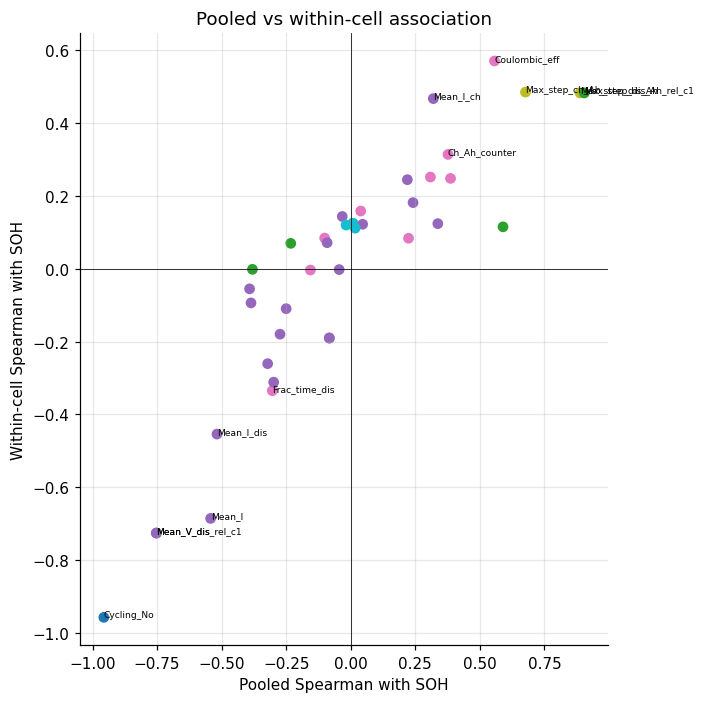

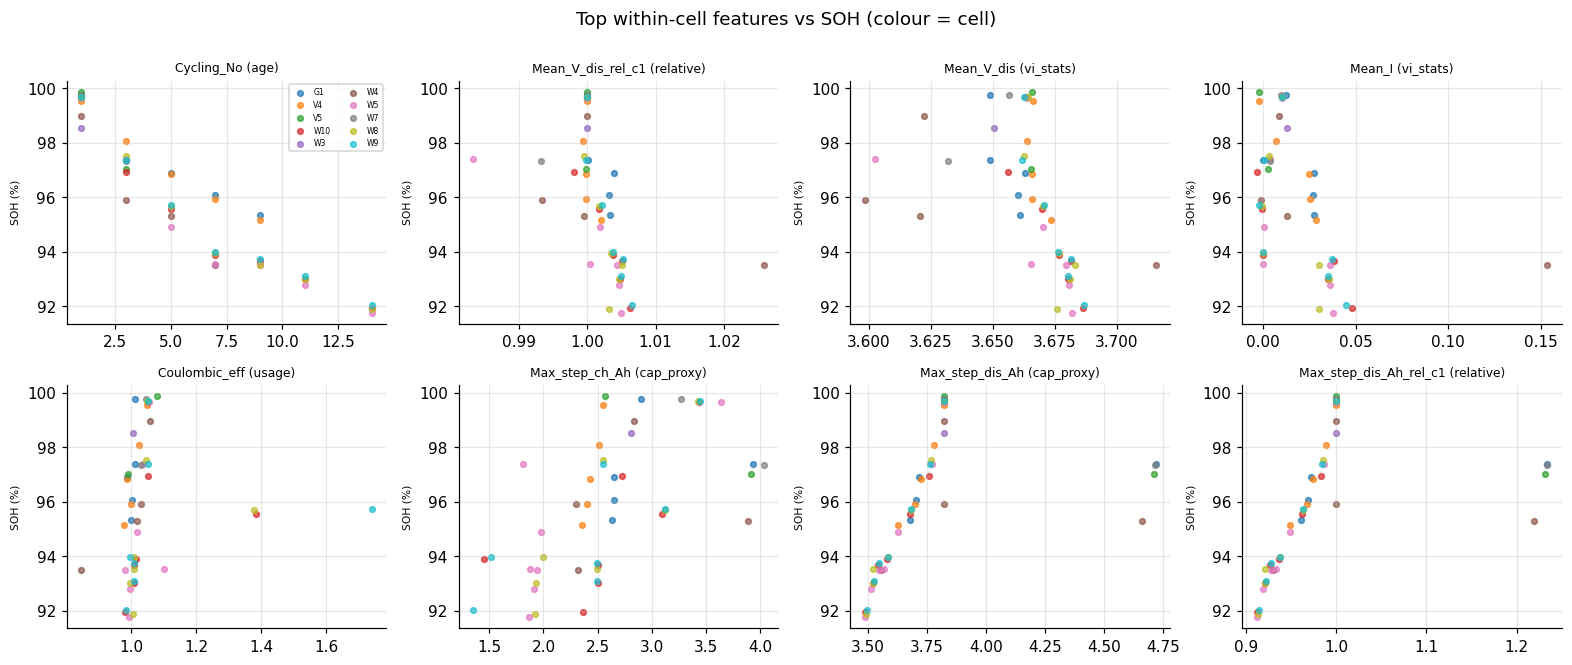

In [ ]:
# ---------- 7.8 between-cell vs within-cell structure (the key issue for LOCO) ----------
def icc1(x, groups):
    x = np.asarray(x, float); grp = pd.Series(groups).reset_index(drop=True)
    k = grp.nunique(); N = len(x)
    means = pd.Series(x).groupby(grp).mean(); ns = grp.value_counts().reindex(means.index)
    gm = x.mean()
    msb = (ns * (means - gm) ** 2).sum() / (k - 1)
    msw = sum(((x[grp == g_] - means[g_]) ** 2).sum() for g_ in means.index) / (N - k)
    n0 = (N - (ns ** 2).sum() / N) / (k - 1)
    return float((msb - msw) / (msb + (n0 - 1) * msw)) if (msb + (n0 - 1) * msw) > 0 else np.nan

multi = data.groupby("Cell_ID").Cycling_No.transform("size") >= 2
dm = data[multi].copy()
dem = dm[FEATURES + [TARGET]] - dm.groupby("Cell_ID")[FEATURES + [TARGET]].transform("mean")   # cell-demeaned

rows = []
for f in FEATURES:
    wr = stats.spearmanr(dem[f], dem[TARGET])[0] if dem[f].std() > 0 else np.nan
    rows.append(dict(Feature=f, Group=GROUP_OF[f], Pooled_spearman=sp.loc[f, TARGET], Within_cell_spearman=wr, ICC_feature=icc1(data[f], data.Cell_ID)))
sig = pd.DataFrame(rows).set_index("Feature")
print(f"ICC of target (share of variance between cells): {icc1(y, data.Cell_ID):.2f}")
print("ICC near 1 = feature mostly identifies the cell; within-cell rho = does it track ageing inside a cell?")
sig = sig.reindex(sig.Within_cell_spearman.abs().sort_values(ascending=False).index)
display(sig.round(3))
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(sig.Pooled_spearman, sig.Within_cell_spearman, c=pd.factorize(sig.Group)[0], cmap="tab10")
for f in sig.index[:12]: ax.annotate(f, (sig.Pooled_spearman[f], sig.Within_cell_spearman[f]), fontsize=6)
ax.axhline(0, c="k", lw=.5); ax.axvline(0, c="k", lw=.5)
ax.set(xlabel="Pooled Spearman with SOH", ylabel="Within-cell Spearman with SOH", title="Pooled vs within-cell association")
fig.tight_layout(); savefig(fig, "18_pooled_vs_within_cell.png"); plt.show()

# ---------- 7.9 key scatter plots ----------
top = list(sig.index[:8])
fig, axs = grid(len(top), ncols=4, w=3.6, h=3)
for ax, f in zip(axs, top):
    for c, gg in data.groupby("Cell_ID"): ax.scatter(gg[f], gg[TARGET], s=14, alpha=.7, label=c)
    ax.set_title(f"{f} ({GROUP_OF[f]})", fontsize=8); ax.set_ylabel("SOH (%)", fontsize=7)
axs[0].legend(ncol=2, fontsize=5)
fig.suptitle("Top within-cell features vs SOH (colour = cell)", y=1.0); fig.tight_layout(); savefig(fig, "19_top_feature_scatter.png"); plt.show()

#7.10 Run preliminary grouped regression benchmarks

Uses battery-level leave-one-group-out predictions to compare simple baselines and ML candidates. These are **EDA diagnostics**, not final model.

,MAE,RMSE,R2
Mean predictor,2.220,2.574,-0.052
Linear: age only (Cycling_No),0.765,0.899,0.872
Ridge: non-age features,1.763,2.621,-0.091
RF: non-age features,0.494,0.711,0.920
"RF: non-age, no cap_proxy",0.505,0.725,0.916
RF: age + non-age,0.366,0.568,0.949


Per-cell MAE (pp):


,Mean predictor,Linear: age only (Cycling_No),Ridge: non-age features,RF: non-age features,"RF: non-age, no cap_proxy",RF: age + non-age
W3,2.70,0.22,1.67,0.77,0.82,1.15
W4,1.51,1.21,3.86,1.10,1.08,1.09
W5,2.67,0.81,2.16,0.51,0.59,0.40
W7,2.79,0.62,1.66,0.72,0.71,0.18
W8,2.46,0.63,1.33,0.26,0.26,0.21
W9,2.36,0.65,1.13,0.22,0.22,0.16
W10,2.38,0.73,1.41,0.16,0.17,0.16
G1,1.51,0.83,2.46,0.92,0.92,0.28
V4,1.60,0.81,0.88,0.31,0.32,0.48
V5,2.68,0.84,1.77,1.19,1.12,0.51


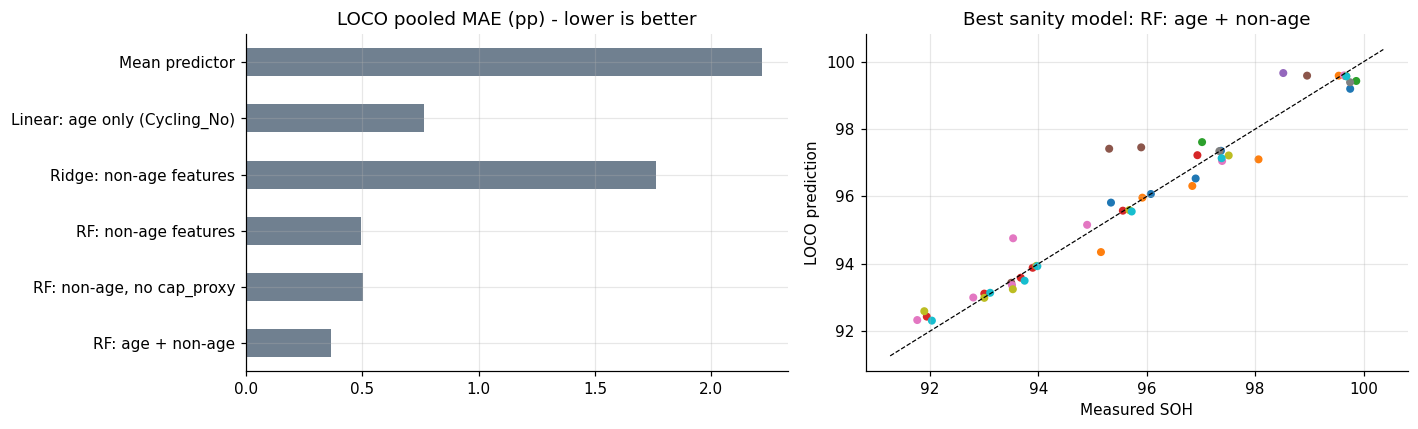

Single-feature linear LOCO R2 (negative = worse than predicting the mean):


,Group,LOCO_R2_linear,Mutual_info
Feature,,,
Cycling_No,age,0.872,1.444
Max_step_ch_Ah,cap_proxy,0.335,0.274
Mean_I_dis,vi_stats,0.226,1.057
Max_step_dis_Ah,cap_proxy,0.123,1.328
Max_step_dis_Ah_rel_c1,relative,0.123,1.340
Mean_V_dis_rel_c1,relative,0.022,0.779
V_p01,vi_stats,0.009,0.323
Std_V_rel_c1,relative,0.007,0.497
Mean_I_ch,vi_stats,0.002,0.036


RF impurity importance (all features, in-sample fit - exploratory only):


,importance
Cycling_No,0.299
Max_step_dis_Ah_rel_c1,0.273
Max_step_dis_Ah,0.268
Mean_I_dis,0.070
Mean_V_dis,0.026
Mean_V_dis_rel_c1,0.019
R_inst_median_rel_c1,0.010
Duration_h,0.010
Mean_I,0.004
Mean_V_rel_c1,0.002


In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import mutual_info_regression

groups = data.Cell_ID.to_numpy(); yv = y.to_numpy()
logo = LeaveOneGroupOut()

def loco_oof(make_model, cols):
    X = data[cols].to_numpy(float); oof = np.zeros(len(data))
    for tr, te in logo.split(X, yv, groups):
        m = make_model(); m.fit(X[tr], yv[tr]); oof[te] = m.predict(X[te])
    return oof

def metrics(oof):
    return dict(MAE=mean_absolute_error(yv, oof), RMSE=np.sqrt(mean_squared_error(yv, oof)), R2=r2_score(yv, oof))

AGE = [f for f in FEATURE_GROUPS["age"] if f in FEATURES]
NONAGE = [f for f in FEATURES if GROUP_OF[f] != "age"]
NOCAP = [f for f in NONAGE if GROUP_OF[f] != "cap_proxy"]
rf = lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))
suite = {
    "Mean predictor":                 (lambda: DummyRegressor(strategy="mean"), ["Cycling_No"]),
    "Linear: age only (Cycling_No)":  (LinearRegression, ["Cycling_No"]),
    # Full-history cumulative Ah excluded: only selected folders are downloaded.
    "Ridge: non-age features":        (ridge, NONAGE),
    "RF: non-age features":           (rf, NONAGE),
    "RF: non-age, no cap_proxy":      (rf, NOCAP),
    "RF: age + non-age":              (rf, FEATURES),
}
res, oofs = {}, {}
for name, (mk, cols) in suite.items():
    cols = [c for c in cols if c in FEATURES]
    if not cols: continue
    oofs[name] = loco_oof(mk, cols); res[name] = metrics(oofs[name])
bench = pd.DataFrame(res).T.round(3)
display(bench)

per_cell = pd.DataFrame({n: pd.Series(np.abs(yv - o)).groupby(groups).mean() for n, o in oofs.items()}).reindex(CELLS_EXPECTED)
print("Per-cell MAE (pp):"); display(per_cell.round(2))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
bench.MAE.plot.barh(ax=axs[0], color="slategray"); axs[0].set(title="LOCO pooled MAE (pp) - lower is better"); axs[0].invert_yaxis()
best = bench.drop("Mean predictor").R2.idxmax()
axs[1].scatter(yv, oofs[best], c=pd.factorize(groups)[0], cmap="tab10", s=18); lim = [yv.min() - .5, yv.max() + .5]
axs[1].plot(lim, lim, "k--", lw=.8); axs[1].set(xlabel="Measured SOH", ylabel="LOCO prediction", title=f"Best sanity model: {best}")
fig.tight_layout(); savefig(fig, "20_loco_benchmark.png"); plt.show()

# single-feature usefulness under LOCO + mutual information
uni = []
mi = mutual_info_regression(StandardScaler().fit_transform(data[FEATURES]), yv, random_state=RANDOM_STATE, n_neighbors=3)
for f, m_ in zip(FEATURES, mi):
    o = loco_oof(LinearRegression, [f]); uni.append(dict(Feature=f, Group=GROUP_OF[f], LOCO_R2_linear=r2_score(yv, o), Mutual_info=m_))
uni = pd.DataFrame(uni).set_index("Feature").sort_values("LOCO_R2_linear", ascending=False)
print("Single-feature linear LOCO R2 (negative = worse than predicting the mean):"); display(uni.round(3))

rf_full = rf().fit(data[FEATURES], yv)
imp = pd.Series(rf_full.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("RF impurity importance (all features, in-sample fit - exploratory only):"); display(imp.head(15).round(3).to_frame("importance"))

## 8 — Export model CSV, full CSV, feature dictionary
* `Pozzato_SOH_Regression_Final.csv` – eligible rows only: IDs, all usable engineered features, both SOH targets. No NaNs, no previous-diagnostic columns.
* `Pozzato_SOH_Full_with_QC.csv` – every cell × period pair with QC flags, prior-diagnostic columns and exclusion reasons.
* `feature_dictionary.csv` – what each column means and its group.
* Use `Cell_ID` as the group key for leave-one-cell-out CV.



Saves the model-ready CSV, an expanded QC table, and a feature dictionary. IDs and both SOH definitions are not all model predictors.

In [ ]:
DICT = {
 "Cycling_No": ("age", "-", "Cycling period index k (inputs from period k, target at Diagnostic k+1)"),
 "Cum_Discharge_Ah": ("age", "Ah", "Cumulative discharge throughput over periods 1..k (counter-based)"),
 "Cum_Throughput_Ah": ("age", "Ah", "Cumulative charge + discharge throughput over periods 1..k"),
 "Cum_Hours": ("age", "h", "Cumulative recorded test time over periods 1..k"),
 "Duration_h": ("usage", "h", "Valid recorded time in period k"),
 "Dis_Ah_counter": ("usage", "Ah", "Discharge Ah in period k from the dis_cap counter (sum of positive increments)"),
 "Ch_Ah_counter": ("usage", "Ah", "Charge Ah in period k from the ch_cap counter"),
 "Coulombic_eff": ("usage", "-", "Ch_Ah_counter / Dis_Ah_counter"),
 "Frac_time_dis": ("usage", "-", "Time fraction with discharge current > 0.05 A"),
 "Frac_time_ch": ("usage", "-", "Time fraction with charge current > 0.05 A"),
 "Frac_time_rest": ("usage", "-", "Time fraction with |I| <= 0.05 A"),
 "N_runs": ("usage", "-", "Number of contiguous step-index runs"),
 "N_steps": ("usage", "-", "Number of distinct step-index values"),
 "Mean_I": ("vi_stats", "A", "Mean current (discharge positive)"), "Std_I": ("vi_stats", "A", "Std of current"),
 "RMS_I": ("vi_stats", "A", "RMS current"), "Mean_abs_I": ("vi_stats", "A", "Mean |current|"),
 "I_p01": ("vi_stats", "A", "1st percentile current"), "I_p05": ("vi_stats", "A", "5th percentile current"),
 "I_p95": ("vi_stats", "A", "95th percentile current"), "I_p99": ("vi_stats", "A", "99th percentile current"),
 "Mean_I_dis": ("vi_stats", "A", "Mean current while discharging"), "Mean_I_ch": ("vi_stats", "A", "Mean current while charging"),
 "Mean_V": ("vi_stats", "V", "Mean voltage (artefact samples excluded)"), "Std_V": ("vi_stats", "V", "Std of voltage"),
 "V_p01": ("vi_stats", "V", "1st percentile voltage"), "V_p05": ("vi_stats", "V", "5th percentile voltage"),
 "V_p50": ("vi_stats", "V", "Median voltage"), "V_p95": ("vi_stats", "V", "95th percentile voltage"),
 "Mean_V_dis": ("vi_stats", "V", "Mean voltage while discharging"), "Mean_V_ch": ("vi_stats", "V", "Mean voltage while charging"),
 "Mean_V_rest": ("vi_stats", "V", "Mean voltage at rest"),
 "R_inst_median": ("resistance", "Ohm", "Median -dV/dI at current steps >= 2 A within 0.5 s (instantaneous resistance)"),
 "R_inst_p25": ("resistance", "Ohm", "25th percentile of the same"), "R_inst_p75": ("resistance", "Ohm", "75th percentile of the same"),
 "R_up_median": ("resistance", "Ohm", "Same, only for current increases (discharge onset)"),
 "R_down_median": ("resistance", "Ohm", "Same, only for current decreases"),
 "R_midV_median": ("resistance", "Ohm", "Same, restricted to 3.6-3.9 V (reduces SOC dependence)"),
 "Max_step_dis_Ah": ("cap_proxy", "Ah", "Largest discharge Ah inside a single step run (capacity-like)"),
 "Max_step_ch_Ah": ("cap_proxy", "Ah", "Largest charge Ah inside a single step run (capacity-like)"),
 "SOH_nominal_pct": ("target", "%", "100 * capacity(Diagnostic k+1) / 4.85 Ah"),
 "SOH_first_pct": ("target", "%", "100 * capacity(Diagnostic k+1) / the cell's own Diagnostic-1 capacity"),
}
for c in REL_BASE:
    DICT[c + "_rel_c1"] = ("relative", "-", f"{c} divided by the same cell's period-1 value")

model_cols = ID_COLS + FEATURES + ["SOH_nominal_pct", "SOH_first_pct"]
final = data[model_cols].copy()
assert final[FEATURES + ["SOH_nominal_pct", "SOH_first_pct"]].notna().all().all()
assert not final.duplicated(["Cell_ID", "Cycling_No"]).any()
assert final.Diag_No.eq(final.Cycling_No + 1).all()
assert final.Cell_ID.nunique() >= 2
final_csv = OUT / "Pozzato_SOH_Regression_Final.csv"
final.to_csv(final_csv, index=False)

full_cols = ID_COLS + [c for c in FEATURES] + [c for c in pairs.columns if c not in model_cols and c not in ("Extractor_version",)]
pairs["Exclusion_reason"] = np.select(
    [~pairs.Target_valid, ~pairs.History_complete, ~elig],
    ["target diagnostic missing/invalid", "earlier cycling file missing", "feature missing/infinite"], default="")
full = pairs[list(dict.fromkeys(full_cols + ["Exclusion_reason", "Candidate_eligible"]))].sort_values(["Cell_ID", "Cycling_No"])
full.to_csv(OUT / "Pozzato_SOH_Full_with_QC.csv", index=False)

fd = pd.DataFrame([dict(Feature=k, Group=v[0], Unit=v[1], Description=v[2]) for k, v in DICT.items()])
fd["In_final_csv"] = fd.Feature.isin(model_cols)
fd.to_csv(OUT / "feature_dictionary.csv", index=False)
print("Final CSV:", final_csv, "|", final.shape)
display(final.head(8))
undoc = [c for c in FEATURES if c not in DICT]
print("Features without dictionary entry:", undoc or "none")

Final CSV: /content/drive/MyDrive/EV_Battery_Research/Pozzato_EDA_v2/Pozzato_SOH_Regression_Final.csv | (47, 45)


,Cell_ID,Cell_Group,Diag_No,Cycling_No,Duration_h,Dis_Ah_counter,Ch_Ah_counter,Coulombic_eff,Frac_time_dis,Frac_time_ch,Frac_time_rest,N_runs,N_steps,Mean_I,Std_I,RMS_I,Mean_abs_I,I_p01,I_p05,I_p95,I_p99,Mean_I_dis,Mean_I_ch,Mean_V,Std_V,V_p01,V_p05,V_p50,V_p95,Mean_V_dis,Mean_V_ch,Mean_V_rest,R_inst_median,R_inst_p25,R_inst_p75,R_down_median,Max_step_dis_Ah,Max_step_ch_Ah,R_inst_median_rel_c1,Max_step_dis_Ah_rel_c1,Mean_V_dis_rel_c1,Mean_V_rel_c1,Std_V_rel_c1,SOH_nominal_pct,SOH_first_pct
0,G1,G,2,1,259.990764,119.899682,121.146960,1.010403,0.354061,0.444170,0.201769,175,12,0.012617,1.699698,1.699745,0.986326,-7.597908,-2.108153,2.186935,3.122604,1.317878,-1.166695,3.783955,0.213026,3.364858,3.435176,3.803992,4.000165,3.648802,3.904375,3.788891,0.038349,0.038184,0.038740,0.038349,3.823950,2.899782,1.000000,1.000000,1.000000,1.000000,1.000000,99.753622,98.673859
1,G1,G,4,3,902.551089,33.245116,33.650527,1.012195,0.028126,0.033801,0.938073,11,9,0.000241,0.381471,0.381471,0.061012,-0.951500,-0.001888,0.000721,1.380516,1.317138,-1.225014,3.986621,0.073980,3.537425,3.999740,3.999997,4.000183,3.649003,3.891160,3.997242,0.041324,0.040658,0.042018,0.041324,4.719479,3.927374,1.077572,1.234189,1.000055,1.053559,0.347280,97.368369,96.314425
2,G1,G,6,5,235.713491,116.517790,115.130564,0.988094,0.380057,0.444801,0.175142,175,12,0.027389,1.835104,1.835308,1.075250,-8.439851,-2.180961,2.222656,3.230255,1.315426,-1.271880,3.767035,0.208453,3.383471,3.439893,3.770932,4.000139,3.662929,3.892634,3.718810,0.031304,0.031126,0.031388,0.031304,3.717574,2.646494,0.816290,0.972181,1.003872,0.995528,0.978535,96.901772,95.852879
3,G1,G,8,7,237.153734,116.053676,116.139085,1.000736,0.376835,0.449131,0.174034,175,12,0.026827,1.809944,1.810143,1.068205,-8.257822,-2.188085,2.215540,3.191406,1.312824,-1.255852,3.766498,0.210478,3.376539,3.434418,3.771718,4.000140,3.660178,3.893484,3.716893,0.032482,0.032339,0.032592,0.032482,3.703671,2.652299,0.847025,0.968546,1.003118,0.995387,0.988037,96.075190,95.035244
4,G1,G,10,9,236.669180,115.197992,115.248748,1.000441,0.374899,0.451763,0.173338,175,12,0.027605,1.794571,1.794784,1.062810,-8.147290,-2.174678,2.214699,3.191536,1.312484,-1.240703,3.767883,0.210630,3.377415,3.435125,3.774763,4.000139,3.660758,3.894284,3.718445,0.032670,0.032508,0.032892,0.032670,3.677262,2.630915,0.851928,0.961640,1.003277,0.995753,0.988752,95.339221,94.307241
5,V4,V,2,1,307.833727,95.916077,100.682546,1.049694,0.239188,0.377068,0.383744,144,12,-0.001857,0.945116,0.945118,0.614201,-1.323151,-1.213640,1.884995,2.824125,1.318293,-0.879719,3.831693,0.194900,3.407538,3.475065,3.906430,4.000414,3.666216,3.811885,3.937945,0.026709,0.026596,0.026985,0.026709,3.823822,2.552856,1.000000,1.000000,1.000000,1.000000,1.000000,99.542029,99.159147
6,V4,V,4,3,395.545673,118.533250,121.396118,1.024152,0.229888,0.354112,0.416000,175,12,0.006943,0.918132,0.918158,0.577261,-1.323151,-1.213045,1.855550,2.800222,1.319188,-0.877769,3.840063,0.195303,3.403507,3.472041,3.934651,4.000414,3.663866,3.810253,3.945024,0.028092,0.027823,0.028168,0.028092,3.781067,2.512529,1.051795,0.988819,0.999359,1.002185,1.002067,98.062276,97.685085
7,V4,V,6,5,266.843377,116.749212,115.219600,0.986898,0.336871,0.508657,0.154472,175,12,0.024857,1.158617,1.158884,0.912006,-1.324699,-1.234924,2.155540,3.068123,1.316356,-0.884872,3.746752,0.190673,3.392723,3.450892,3.740786,4.000103,3.665738,3.812167,3.718701,0.030625,0.030595,0.030689,0.030625,3.724845,2.433466,1.146622,0.974116,0.999870,0.977832,0.978311,96.839938,96.467449


Features without dictionary entry: none


## 9 — Validate the exported CSV independently



Reloads the CSV from disk, then checks schema, diagnostic alignment, missingness, and uniqueness. This verifies the actual artifact rather than only the in-memory table.

In [ ]:
ex = pd.read_csv(final_csv)
assert ex.columns.tolist() == model_cols
assert ex[FEATURES + ["SOH_nominal_pct", "SOH_first_pct"]].notna().all().all()
assert np.isfinite(ex[FEATURES + ["SOH_nominal_pct", "SOH_first_pct"]].to_numpy(float)).all()
assert ex.Diag_No.eq(ex.Cycling_No + 1).all() and not ex.duplicated(["Cell_ID", "Cycling_No"]).any()
assert not set(FEATURES) & set(TARGET_COLS + PRIOR_DIAG + ID_COLS)
print(f"PASS: {len(ex)} rows | {ex.Cell_ID.nunique()} cells | {len(FEATURES)} features")
folds = ex.groupby("Cell_ID").size().reindex(CELLS_EXPECTED).dropna().astype(int)
print("LOCO plan (rows held out per fold):", folds.to_dict())
excl = full[~full.Candidate_eligible].Exclusion_reason.value_counts()
print("Rows excluded from the model CSV by reason:", excl.to_dict() if len(excl) else "none")

PASS: 47 rows | 10 cells | 40 features
LOCO plan (rows held out per fold): {'W3': 1, 'W4': 4, 'W5': 7, 'W7': 2, 'W8': 7, 'W9': 7, 'W10': 7, 'G1': 5, 'V4': 5, 'V5': 2}
Rows excluded from the model CSV by reason: none


#### Review training-readiness checks

Reports completeness and quality thresholds. Some checks use conservative study-specific cutoffs; explain any FAIL before interpreting it as an invalid dataset.

In [ ]:
# ===== READINESS GATE: run after the CSV validation cell, before training =====
got_keys = set(zip(cycling_features.Cell.astype(str), cycling_features.Cycling.astype(int)))
n_target_pairs = int(pairs.Target_valid.sum())
checks = {
    "All selected cycling files extracted": len(selected_keys - got_keys) == 0,
    "Selected periods match measured diagnostics (chronology)": bool(CHRONOLOGY_CONSISTENT),
    "Current sign uniform and consistent in every file": bool(cycling_features.Current_sign_discharge.nunique() == 1
                                                              and cycling_features.Sign_consistent.all()),
    "Charge/discharge counters agree with integrated current (0.98-1.02)":
        bool(cycling_features[["Dis_counter_vs_integral", "Ch_counter_vs_integral"]].stack().between(0.98, 1.02).all()),
    "CSV has one row per valid target pair": len(ex) == n_target_pairs,
    "CSV has no NaN / inf in features or targets": bool(np.isfinite(ex[FEATURES + ["SOH_nominal_pct", "SOH_first_pct"]].to_numpy(float)).all()),
    "No duplicate (Cell_ID, Cycling_No)": not ex.duplicated(["Cell_ID", "Cycling_No"]).any(),
    "All 10 cells present (needed for leave-one-cell-out)": ex.Cell_ID.nunique() == len(CELLS_EXPECTED),
    "Imputed rows <= 15 % of the data": float(pairs.loc[elig, "Any_feature_imputed"].mean()) <= 0.15,
}
for k, v in checks.items(): print(("PASS  " if v else "FAIL  ") + k)
print(f"\nRows {len(ex)} | cells {ex.Cell_ID.nunique()} | features {len(FEATURES)} | rows per feature {len(ex)/len(FEATURES):.1f}")
if len(ex) / len(FEATURES) < 5:
    print("NOTE: fewer than 5 rows per feature - train with a short feature list (see the shortlist) and regularised / shallow models.")
print("\n>>> READY TO TRAIN with Pozzato_SOH_Regression_Final.csv" if all(checks.values())
      else "\n>>> NOT READY: fix the FAIL lines above first")

PASS  All selected cycling files extracted
PASS  Selected periods match measured diagnostics (chronology)
PASS  Current sign uniform and consistent in every file
FAIL  Charge/discharge counters agree with integrated current (0.98-1.02)
PASS  CSV has one row per valid target pair
PASS  CSV has no NaN / inf in features or targets
PASS  No duplicate (Cell_ID, Cycling_No)
PASS  All 10 cells present (needed for leave-one-cell-out)
FAIL  Imputed rows <= 15 % of the data

Rows 47 | cells 10 | features 40 | rows per feature 1.2
NOTE: fewer than 5 rows per feature - train with a short feature list (see the shortlist) and regularised / shallow models.

>>> NOT READY: fix the FAIL lines above first


## 10 — Save Findings summary
Collects selected-file coverage, diagnostic alignment, feature shortlist, and preliminary model metrics in a JSON summary.

In [ ]:
import pandas as pd
import numpy as np
import json

# ==========================================
# 1. RESTORE CYCLING EXTRACTION COUNTS
# ==========================================

SELECTED_CYCLING = [1, 3, 5, 7, 9, 11, 14]

# Load saved cycling features
cycling_features = pd.read_csv(
    OUT / "cycling_features_v4.csv"
)

# Count successfully extracted selected files
selected_features = cycling_features[
    cycling_features["Cycling"].astype(int).isin(SELECTED_CYCLING)
]

got = set(zip(
    selected_features["Cell"].astype(str),
    selected_features["Cycling"].astype(int)
))

# Check the original file inventory if available
if "cycling_index" in globals():

    selected_index = cycling_index[
        cycling_index["Cycling"].astype(int).isin(SELECTED_CYCLING)
    ]

    expected = set(zip(
        selected_index["Cell"].astype(str),
        selected_index["Cycling"].astype(int)
    ))

    missing_keys = sorted(expected - got)

else:
    expected = None
    missing_keys = []

# ==========================================
# 2. FEATURE SHORTLIST
# ==========================================

within = sig.Within_cell_spearman.abs().sort_values(
    ascending=False
)

shortlist = []

for f in within.index:

    if np.isnan(within[f]) or within[f] < 0.3:
        break

    if all(
        abs(sp.loc[f, s_]) <= 0.95
        for s_ in shortlist
    ):
        shortlist.append(f)

# ==========================================
# 3. BASELINE MODEL COMPARISON
# ==========================================

age_r2 = bench.loc[
    "Linear: age only (Cycling_No)", "R2"
]

best_nonage = bench.loc[
    [
        "Ridge: non-age features",
        "RF: non-age features",
        "RF: non-age, no cap_proxy"
    ],
    "R2"
].max()

# ==========================================
# 4. CREATE EDA SUMMARY
# ==========================================

summary = {

    "rows": int(len(ex)),

    "cells": int(ex.Cell_ID.nunique()),

    "features": len(FEATURES),

    "selected_cycling_folders": SELECTED_CYCLING,

    "cycling_files_expected": (
        len(expected) if expected is not None else None
    ),

    "cycling_files_extracted": len(got),

    "cycling_files_missing": (
        len(missing_keys) if expected is not None else None
    ),

    "chronology_consistent_with_data": CHRONOLOGY_CONSISTENT,

    "target": TARGET,

    "target_mean": float(y.mean()),

    "target_sd": float(y.std()),

    "loco_pooled_metrics": bench.to_dict(orient="index"),

    "shortlist_within_cell_signal": shortlist,

    "high_vif_features": vif[vif > 10].index.tolist(),

    "constant_features_dropped": dropped,

    "current_sign_uniform": bool(
        cycling_features["Current_sign_discharge"].nunique() == 1
        and cycling_features["Sign_consistent"].all()
    )
}

# ==========================================
# 5. SAVE EDA SUMMARY
# ==========================================

with open(OUT / "eda_summary.json", "w") as fh:
    json.dump(summary, fh, indent=2, default=float)

# ==========================================
# 6. DISPLAY FINAL RESULTS
# ==========================================

expected_text = (
    str(len(expected))
    if expected is not None
    else "Unknown (inventory not loaded)"
)

print("========== FINAL EDA SUMMARY ==========")

print("Rows:", summary["rows"])
print("Cells:", summary["cells"])
print("Candidate features:", summary["features"])

print("Selected Cycling:", SELECTED_CYCLING)

print("Cycling files extracted:",
      len(got), "/", expected_text)

print("Missing files:",
      len(missing_keys) if expected is not None else "Unknown")

print("Chronology consistent:",
      CHRONOLOGY_CONSISTENT)

print("Current sign uniform:",
      summary["current_sign_uniform"])

print("\n========== MODEL RESULTS ==========")

print(f"Age-only Linear Regression R²: {age_r2:.3f}")
print(f"Best non-age Regression R²: {best_nonage:.3f}")

print("\nShortlisted features:")
print(shortlist if shortlist else "No features met the threshold")

if best_nonage > age_r2 + 0.05:
    print("\nConclusion: Non-age features improve prediction.")
else:
    print("\nConclusion: Non-age features do not clearly outperform age alone.")

print("\nEDA summary saved to:", OUT / "eda_summary.json")

========== FINAL EDA SUMMARY ==========
Rows: 47
Cells: 10
Candidate features: 40
Selected Cycling: [1, 3, 5, 7, 9, 11, 14]
Cycling files extracted: 47 / 47
Missing files: 0
Chronology consistent: True
Current sign uniform: True

========== MODEL RESULTS ==========
Age-only Linear Regression R²: 0.872
Best non-age Regression R²: 0.920

Shortlisted features:
['Cycling_No', 'Mean_V_dis_rel_c1', 'Mean_V_dis', 'Mean_I', 'Coulombic_eff', 'Max_step_ch_Ah', 'Max_step_dis_Ah', 'Mean_I_ch', 'Mean_I_dis', 'Frac_time_dis', 'Ch_Ah_counter']

Conclusion: Non-age features do not clearly outperform age alone.

EDA summary saved to: /content/drive/MyDrive/EV_Battery_Research/Pozzato_EDA_v2/eda_summary.json
